# S2 · Systemic financial crisis: what the 2008–2013 crisis did to trust, satisfaction with democracy and the vote

**What this notebook does.** It is the full analysis that the earlier notebook (`Shock_2_financial_crisis.ipynb`) set up and froze but did not run. It uses **all 27 EU countries**, not four reference episodes, because severity differed enormously from country to country (unemployment rose by 19.6 points in Greece and fell by half a point in Germany), so *how hard a country was hit* can be measured and related to what happened afterwards.

**The design, in three layers**
1. **Cross-country test (the frozen plan).** Baseline 2006–07, follow-up 2012–13 and 2014–15; main severity measure the **rise in unemployment** from 2007 to its peak; main outcomes trust in parliament, the radical vote and the populist vote; the controls and tests named in advance. Every other combination is reported but labelled exploratory.
2. **Panel through time.** Severity as it built up (peak-to-date and current), country by wave, so the path before, during and after the crisis can be seen and the cross-country result checked against within-country movements.
3. **All elections.** 140 pairs of consecutive elections in 27 countries (2001–2023), so the vote result does not rest on one election per country.

**Then the tests that matter for a stress test:** hold out the six hardest-hit countries and predict them; hold out France; leave one country out at a time and score against "no change"; a pre-crisis placebo.

**What is new beyond the frozen plan** (the specification asks for these, and the earlier notebook listed them as "to add"):
- **Radical and populist vote for every EU country**, built by joining PopuList (party classes) to ParlGov (vote shares) on the ParlGov party id (`src/build_radical_vote_panel.py`). Before, it existed for eight countries.
- **Monthly unemployment, quarterly GDP and monthly bond yields** from Eurostat, so severity is dated and can be measured at any wave.
- **The ESRB/ECB financial-crises database** for each country's crisis start, length, and whether the sovereign was involved.

The IMF banking-crises database (Laeven and Valencia) refuses automated downloads (HTTP 403), so fiscal cost and output loss from it are not used; the debt jump and the bailout programmes stand in for the fiscal cost.

**Reading rules (as in the other notebooks).** An interpretation, not a prediction: *if a crisis like this hit, past episodes suggest changes within this range.* Survey changes inside about ±4.4 points are not read as a direction. Ranges are 90%. France is a held-out case for the checks.

In [1]:
import json, itertools, sys, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTDIR = ROOT / 'outputs/model'
OUTDIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.max_columns', 40, 'display.width', 230, 'display.max_rows', 200, 'display.max_colwidth', 70)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREY, RED, LIGHT, ORANGE, GREEN = '#2b6cb0', '#8a8f98', '#c53030', '#e8ecf1', '#dd8a2e', '#2a8c82'
NOISE = 4.4
RNG_SEED = 20261124

EUROSTAT_ISO3 = {'AT': 'AUT', 'BE': 'BEL', 'BG': 'BGR', 'CY': 'CYP', 'CZ': 'CZE', 'DE': 'DEU', 'DK': 'DNK', 'EE': 'EST', 'EL': 'GRC', 'ES': 'ESP', 'FI': 'FIN', 'FR': 'FRA',
                 'HR': 'HRV', 'HU': 'HUN', 'IE': 'IRL', 'IT': 'ITA', 'LT': 'LTU', 'LU': 'LUX', 'LV': 'LVA', 'MT': 'MLT', 'NL': 'NLD', 'PL': 'POL', 'PT': 'PRT', 'RO': 'ROU',
                 'SE': 'SWE', 'SI': 'SVN', 'SK': 'SVK'}
EB_ISO3 = {**EUROSTAT_ISO3, 'GR': 'GRC'}
ISO3 = sorted(EUROSTAT_ISO3.values())
NEW_MEMBERS = {'CYP', 'CZE', 'EST', 'HUN', 'LTU', 'LVA', 'MLT', 'POL', 'SVK', 'SVN', 'BGR', 'ROU', 'HRV'}       # joined in 2004 or later
EURO_2007 = {'AUT', 'BEL', 'DEU', 'ESP', 'FIN', 'FRA', 'IRL', 'ITA', 'LUX', 'NLD', 'PRT', 'GRC', 'SVN'}            # euro members at the start of 2008
STRESS = ['GRC', 'IRL', 'PRT', 'ESP', 'ITA', 'CYP']          # the reference episodes (euro-area 2008-13) plus Cyprus
HELD_OUT = 'FRA'
LEHMAN = pd.Timestamp('2008-09-15')

def decode(path):
    d = json.load(open(path)); ids, sizes = d['id'], d['size']
    cats = [list(d['dimension'][k]['category']['index']) for k in ids]
    rows = []
    for pos, combo in enumerate(itertools.product(*[range(s) for s in sizes])):
        v = d['value'].get(str(pos))
        if v is not None:
            rows.append({k: cats[i][combo[i]] for i, k in enumerate(ids)} | {'value': v})
    return pd.DataFrame(rows)

def t90(df):
    z = 1.6448536
    return z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)

## 1. How hard was each country hit?

Severity is measured from Eurostat series that are **not themselves political outcomes**, each dated, for every EU country:

| Measure | Definition |
| --- | --- |
| **Unemployment rise** (main, frozen in advance) | Peak of the 3-month average unemployment rate between 2008 and 2014, minus the 2007 average, in points |
| GDP below its 2007 level | Worst quarter of 2008–2014 against the 2007 average, % (0 where output never fell below 2007) |
| Sovereign spread | Peak 10-year government bond yield over Germany's, 2008–2014, basis points (no Estonian series) |
| Debt jump | Government debt as % of GDP in 2013 minus 2007, points |
| Bailout programme | An EC/IMF/ESM programme (the team's table) |
| Banking crisis (ESRB/ECB) | Whether the European Systemic Risk Board's database lists a systemic crisis starting 2007–2013, its start, how long crisis management lasted, and whether the sovereign was involved |

The three **controls** named in the plan (besides trust or radical vote before the crisis) are euro membership at the start of 2008, income per head in 2007, and, for the subgroup check, whether a country joined the EU in 2004 or later.

In [2]:
S2DIR = ROOT / 'data/raw/eurostat_s2'
U = decode(S2DIR / 'une_rt_m_monthly_unemployment.json'); U = U[U.geo.isin(EUROSTAT_ISO3)]
U = U.assign(m=pd.PeriodIndex(U.time, freq='M'), iso3=U.geo.map(EUROSTAT_ISO3)).pivot(index='m', columns='iso3', values='value')
Y = decode(S2DIR / 'irt_lt_mcby_m_monthly_bond_yield.json'); Y = Y[Y.geo.isin(EUROSTAT_ISO3)]
Y = Y.assign(m=pd.PeriodIndex(Y.time, freq='M'), iso3=Y.geo.map(EUROSTAT_ISO3)).pivot(index='m', columns='iso3', values='value')
G = decode(S2DIR / 'namq_10_gdp_quarterly_real.json'); G = G[G.geo.isin(EUROSTAT_ISO3)]
G = G.assign(q=pd.PeriodIndex(G.time, freq='Q'), iso3=G.geo.map(EUROSTAT_ISO3)).pivot(index='q', columns='iso3', values='value')
U3 = U.rolling(3, min_periods=3).mean()
SPREAD = Y.sub(Y['DEU'], axis=0) * 100

u_base = U.loc['2007-01':'2007-12'].mean()
g_base = G.loc['2007Q1':'2007Q4'].mean()
sev = pd.DataFrame({
    'u_base_pct': u_base,
    'u_rise': U3.loc['2008-01':'2014-12'].max() - u_base,
    'u_peak_month': U3.loc['2008-01':'2014-12'].idxmax().astype(str),
    'gdp_below_2007': (-(G.loc['2008Q1':'2014Q4'].min() / g_base - 1) * 100).clip(lower=0),
    'spread_peak_bp': SPREAD.loc['2008-01':'2014-12'].max(),
}).loc[ISO3]

inputs = pd.read_csv(ROOT / 'data/processed/s2_country_year_inputs.csv')
yr = lambda col, y: inputs[inputs.year == y].set_index('iso3')[col]
sev['debt_jump'] = (yr('gov_10dd_edpt1_debt_gdp', 2013) - yr('gov_10dd_edpt1_debt_gdp', 2007)).reindex(ISO3)
sev['income_2007'] = yr('gdp_per_head_real_eur', 2007).reindex(ISO3)
bail = pd.read_csv(ROOT / 'data/processed/s2_bailout_country.csv'); bail['iso3'] = bail.geo.map(EB_ISO3)
sev['bailout'] = bail.set_index('iso3').had_programme.reindex(ISO3).astype(int)
sev['euro'] = [int(c in EURO_2007) for c in ISO3]; sev['new_member'] = [int(c in NEW_MEMBERS) for c in ISO3]

esrb = pd.read_excel(ROOT / 'data/raw/financial_crises/esrb_fcdb_20220120.xlsx', sheet_name='Systemic crises').iloc[1:]
esrb.columns = ['country', 'event', 'start', 'end_mgmt', 'back_normal', 'systemic', 'accelerator', 'description', 'policies', 'external_support', 'dom_vs_imp', 'first_default', 'currency', 'sovereign', 'banking', 'asset_price', 'transition', 'macropru', 'macropru_expl']
esrb['iso3'] = esrb.country.astype(str).str.strip().map({**EB_ISO3, 'UK*': 'GBR'})
esrb = esrb.dropna(subset=['iso3']); esrb['start_m'] = esrb.start.astype(str).str[:7]
gfc = esrb[(esrb.start_m >= '2007-01') & (esrb.start_m <= '2013-12') & (esrb.systemic == 1)].drop_duplicates('iso3').set_index('iso3')
sev['esrb_crisis'] = [int(c in gfc.index) for c in ISO3]
sev['esrb_start'] = [gfc.start_m.get(c, '') for c in ISO3]
sev['esrb_months'] = [(pd.Period(str(gfc.end_mgmt[c])[:7], 'M') - pd.Period(gfc.start_m[c], 'M')).n if c in gfc.index else np.nan for c in ISO3]
sev['esrb_sovereign'] = [int(gfc.sovereign.get(c, 0) == 1) for c in ISO3]
print(f"{len(sev)} countries. ESRB lists a systemic crisis starting 2007-13 in {int(sev.esrb_crisis.sum())} of them; the sovereign was involved in {int(sev.esrb_sovereign.sum())}.")
display(sev.sort_values('u_rise', ascending=False).round(1))

27 countries. ESRB lists a systemic crisis starting 2007-13 in 20 of them; the sovereign was involved in 8.


,u_base_pct,u_rise,u_peak_month,gdp_below_2007,spread_peak_bp,debt_jump,income_2007,bailout,euro,new_member,esrb_crisis,esrb_start,esrb_months,esrb_sovereign
iso3,,,,,,,,,,,,,,
GRC,8.4,19.6,2013-09,27.3,2739.0,75.8,22370.0,1,1,0,1,2010-05,99.0,1
ESP,8.2,18.1,2013-04,7.8,555.0,64.3,24530.0,1,1,0,1,2009-03,57.0,1
EST,4.5,14.6,2010-04,19.8,NaN,7.5,13230.0,0,0,1,0,,NaN,0
LVA,6.0,14.6,2010-02,22.2,1061.0,32.9,10220.0,1,0,1,1,2008-11,21.0,0
LTU,4.3,14.0,2010-07,13.8,1148.0,23.0,9760.0,0,0,1,1,2008-12,11.0,0
CYP,3.9,12.8,2013-10,7.8,580.0,52.6,24420.0,1,0,1,1,2011-06,57.0,1
IRL,5.0,11.0,2012-04,11.1,971.0,93.8,41210.0,1,1,0,1,2008-09,63.0,1
PRT,9.6,8.8,2013-03,8.7,1203.0,58.1,17250.0,1,1,0,1,2008-10,86.0,1
HRV,9.6,8.1,2014-04,9.5,574.0,42.4,11370.0,0,0,1,1,2007-09,57.0,1


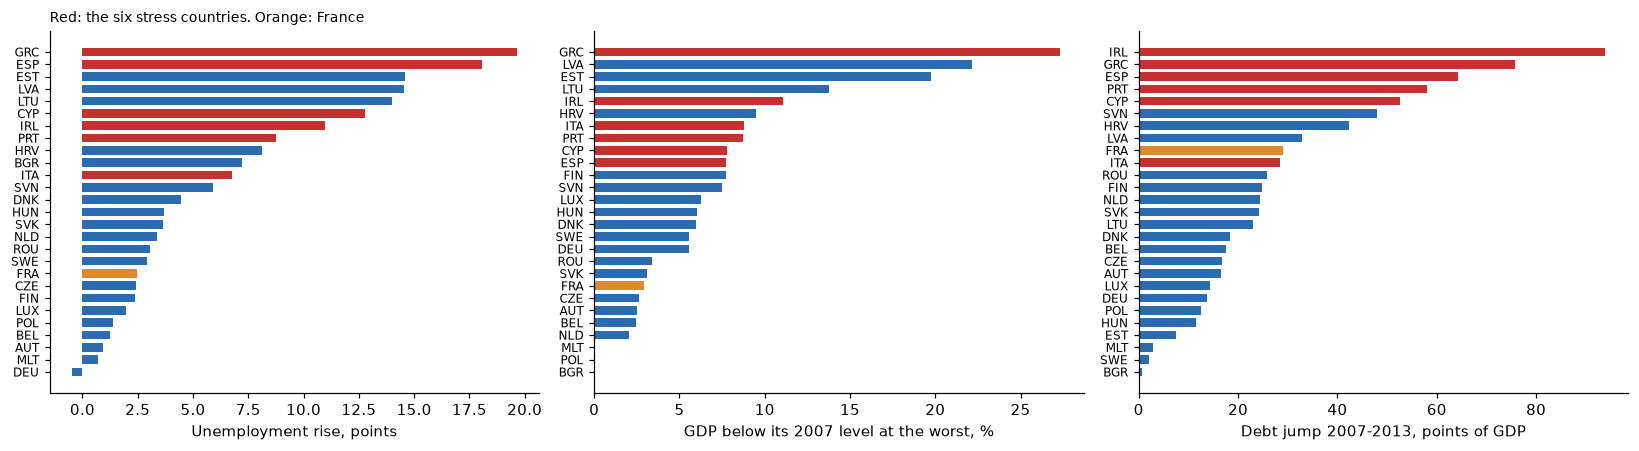

Correlation between the severity measures (rank):


,u_rise,gdp_below_2007,spread_peak_bp,debt_jump
u_rise,1.00,0.77,0.75,0.56
gdp_below_2007,0.77,1.00,0.62,0.58
spread_peak_bp,0.75,0.62,1.00,0.56
debt_jump,0.56,0.58,0.56,1.00


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (col, lab) in zip(axes, [('u_rise', 'Unemployment rise, points'), ('gdp_below_2007', 'GDP below its 2007 level at the worst, %'), ('debt_jump', 'Debt jump 2007-2013, points of GDP')]):
    s = sev[col].sort_values(ascending=True)
    ax.barh(s.index, s.values, color=[RED if c in STRESS else (ORANGE if c == HELD_OUT else BLUE) for c in s.index], height=0.7)
    ax.set_xlabel(lab); ax.tick_params(axis='y', labelsize=8)
axes[0].set_title('Red: the six stress countries. Orange: France', fontsize=9, loc='left')
plt.tight_layout(); plt.show()
print('Correlation between the severity measures (rank):'); display(sev[['u_rise', 'gdp_below_2007', 'spread_peak_bp', 'debt_jump']].corr(method='spearman').round(2))

## 2. What happened afterwards: trust, satisfaction with democracy, the vote

**Survey outcomes** (Eurobarometer, `eb_panel.csv`): the average of the waves with fieldwork in a window, and the change from the **baseline 2006–07** to **2012–13** (the main follow-up) and **2014–15** (late). Four outcomes: trust in parliament, in government, in parties, and satisfaction with democracy.

**Vote outcomes**: for each country, the last parliamentary election up to the end of 2007 and the first one between January 2011 and June 2015 (the frozen window). The **radical vote** is the far-right plus far-left share, the **populist vote** PopuList's populist class, both from the new all-EU table (strict version: parties PopuList flags as borderline are left out). **Effective number of parties and turnout** come from PPEG (alliance members count as one list), with compulsory-voting elections left out of turnout.

The radical-vote table was checked against the team's own eight-country table, which it agrees with within 2 points in two thirds of the 48 elections both cover (`data/processed/radical_vote_panel_check.csv`). Differences come mostly from Portugal and Belgium, where the team's table counts parties that PopuList marks borderline.

In [4]:
eb = pd.read_csv(ROOT / 'data/processed/eb_panel.csv', parse_dates=['fieldwork_median'])
eb['iso3'] = eb.country.map(EB_ISO3); eb = eb.dropna(subset=['iso3'])
SURVEY = {'trust_parl': ('trust_parl_pct', 'Trust in parliament'), 'trust_gov': ('trust_gov_pct', 'Trust in government'),
          'trust_parties': ('trust_parties_pct', 'Trust in political parties'), 'swd': ('swd_pct', 'Satisfied with democracy')}
def window_mean(col, a, b):
    d = eb[(eb.fieldwork_median >= a) & (eb.fieldwork_median <= b)]
    return d.groupby('iso3')[col].mean()
out = pd.DataFrame(index=ISO3)
for k, (col, label) in SURVEY.items():
    out[f'{k}_before'] = window_mean(col, '2006-01-01', '2007-12-31')
    out[f'd_{k}'] = window_mean(col, '2012-01-01', '2013-12-31') - out[f'{k}_before']
    out[f'd_{k}_late'] = window_mean(col, '2014-01-01', '2015-12-31') - out[f'{k}_before']

rp = pd.read_csv(ROOT / 'data/processed/radical_vote_panel.csv', parse_dates=['election_date'])
import build_s1_dataset as b1
et = b1.election_table().rename(columns={'iso3c': 'iso3', 'edate': 'election_date'})
rp = rp.merge(et[['iso3', 'election_date', 'turnout_pct', 'effective_parties', 'compulsory_voting']].assign(election_date=lambda d: d.election_date), on=['iso3', 'election_date'], how='left')
for i in rp.index[rp.effective_parties.isna()]:          # PPEG and ParlGov can differ by a day
    near = et[(et.iso3 == rp.at[i, 'iso3']) & ((et.election_date - rp.at[i, 'election_date']).abs() <= pd.Timedelta(days=5))]
    if len(near): rp.loc[i, ['turnout_pct', 'effective_parties', 'compulsory_voting']] = near.iloc[0][['turnout_pct', 'effective_parties', 'compulsory_voting']].to_numpy()
VOTE = {'radical': 'radical_pct', 'farright': 'farright_pct', 'farleft': 'farleft_pct', 'populist': 'populist_pct', 'enp': 'effective_parties', 'turnout': 'turnout_pct'}
for k, col in VOTE.items():
    pre = rp[rp.election_date <= '2007-12-31'].sort_values('election_date').groupby('iso3').tail(1).set_index('iso3')
    post = rp[(rp.election_date >= '2011-01-01') & (rp.election_date <= '2015-06-30')].sort_values('election_date').groupby('iso3').head(1).set_index('iso3')
    ch = post[col] - pre[col]
    if k == 'turnout':
        ch = ch.where(~(pre.compulsory_voting.astype(bool) | post.compulsory_voting.astype(bool)))
    out[f'd_{k}'] = ch; out[f'{k}_before'] = pre[col]
out['pre_election'] = rp[rp.election_date <= '2007-12-31'].sort_values('election_date').groupby('iso3').election_date.last().dt.date
out['post_election'] = rp[(rp.election_date >= '2011-01-01') & (rp.election_date <= '2015-06-30')].sort_values('election_date').groupby('iso3').election_date.first().dt.date
df = sev.join(out); df['log_income'] = np.log(df.income_2007)
print('Countries with a usable change, by outcome:'); display(pd.DataFrame({k: [int(df[c].notna().sum())] for k, c in [(l, f'd_{k}') for k, (_, l) in SURVEY.items()] + [('Radical vote', 'd_radical'), ('Populist vote', 'd_populist'), ('Effective parties', 'd_enp'), ('Turnout', 'd_turnout')]}, index=['countries']))
display(df[['u_rise', 'd_trust_parl', 'd_trust_gov', 'd_trust_parties', 'd_swd', 'd_radical', 'd_farright', 'd_farleft', 'd_populist', 'd_enp', 'd_turnout']].sort_values('u_rise', ascending=False).round(1))

Countries with a usable change, by outcome:


,Trust in parliament,Trust in government,Trust in political parties,Satisfied with democracy,Radical vote,Populist vote,Effective parties,Turnout
countries,27,27,27,27,27,27,25,21


,u_rise,d_trust_parl,d_trust_gov,d_trust_parties,d_swd,d_radical,d_farright,d_farleft,d_populist,d_enp,d_turnout
iso3,,,,,,,,,,,
GRC,19.6,-39.9,-33.0,-16.8,-44.6,28.8,16.7,12.1,21.5,4.5,NaN
ESP,18.1,-32.9,-33.5,-20.8,-44.5,1.9,0.0,1.9,0.0,0.3,-6.7
EST,14.6,-12.2,-18.7,-2.5,-7.4,-5.0,-5.0,0.0,-5.0,-0.3,1.6
LVA,14.6,-6.3,-5.9,-1.2,0.1,6.9,6.9,0.0,4.4,-2.2,-1.6
LTU,14.0,-3.3,-2.9,2.7,-2.3,0.0,0.0,0.0,-24.5,NaN,NaN
CYP,12.8,-32.7,-33.0,-11.3,-27.5,-0.8,-0.8,0.0,0.0,-0.4,NaN
IRL,11.0,-20.1,-19.2,-12.7,-21.2,0.6,0.0,0.6,3.0,0.7,2.9
PRT,8.8,-21.5,-19.5,-4.1,-14.6,0.0,0.0,0.0,0.0,0.5,-6.2
HRV,8.1,-4.2,0.1,0.1,-7.9,-0.4,-0.4,0.0,5.4,0.2,-2.3


## 3. The cross-country test (the frozen plan)

**Question:** did countries where unemployment rose more see trust fall more, and the radical or populist vote rise more, between 2006–07 and 2012–13?

For each outcome: the **rank correlation** with the unemployment rise (with a permutation p-value, 10,000 shuffles), the **slope** per point of unemployment (OLS, no controls and with the four frozen controls: the outcome's level before, euro membership, log income per head, and the radical vote before), and a **90% range from resampling countries** (4,000 draws). The three **main outcomes** are trust in parliament, the radical vote and the populist vote; the p-value is multiplied by 3 for them (Bonferroni), and by 9 for all outcomes together.

In [5]:
def rank_corr(x, y):
    return float(np.corrcoef(pd.Series(x).rank(), pd.Series(y).rank())[0, 1])
def perm_p(x, y, B=10000, seed=RNG_SEED):
    rng = np.random.default_rng(seed); r = rank_corr(x, y); xr, yr = pd.Series(x).rank().to_numpy(), pd.Series(y).rank().to_numpy()
    perm = np.array([np.corrcoef(xr, rng.permutation(yr))[0, 1] for _ in range(B)])
    return r, float((np.abs(perm) >= abs(r) - 1e-12).mean())
def fit_ols(y, X):
    Xm = np.column_stack([np.ones(len(y)), X]); b = np.linalg.lstsq(Xm, y, rcond=None)[0]; e = y - Xm @ b
    XtXi = np.linalg.pinv(Xm.T @ Xm); h = np.einsum('ij,jk,ik->i', Xm, XtXi, Xm)
    V = XtXi @ (Xm.T * (e / (1 - h)) ** 2 @ Xm) @ XtXi
    return b, np.sqrt(np.diag(V))
def boot_slope(d, ycol, xcols, B=4000, seed=RNG_SEED):
    rng = np.random.default_rng(seed); Y_, X_ = d[ycol].to_numpy(), d[xcols].to_numpy(); n = len(d); s = []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if np.ptp(X_[i, 0]) == 0: continue
        s.append(np.linalg.lstsq(np.column_stack([np.ones(n), X_[i]]), Y_[i], rcond=None)[0][1])
    return np.quantile(s, [0.05, 0.95])

FAMILY = {'d_trust_parl': 'main', 'd_radical': 'main', 'd_populist': 'main', 'd_trust_gov': 'secondary', 'd_trust_parties': 'secondary', 'd_swd': 'secondary',
          'd_farright': 'secondary', 'd_farleft': 'secondary', 'd_enp': 'secondary', 'd_turnout': 'secondary'}
LABEL = {'d_trust_parl': 'Trust in parliament', 'd_trust_gov': 'Trust in government', 'd_trust_parties': 'Trust in parties', 'd_swd': 'Satisfied with democracy',
         'd_radical': 'Radical vote (far right + far left)', 'd_farright': 'Far-right vote', 'd_farleft': 'Far-left vote', 'd_populist': 'Populist vote', 'd_enp': 'Effective number of parties', 'd_turnout': 'Turnout (pp)'}
BEFORE = {'d_trust_parl': 'trust_parl_before', 'd_trust_gov': 'trust_gov_before', 'd_trust_parties': 'trust_parties_before', 'd_swd': 'swd_before', 'd_radical': 'radical_before',
          'd_farright': 'farright_before', 'd_farleft': 'farleft_before', 'd_populist': 'populist_before', 'd_enp': 'enp_before', 'd_turnout': 'turnout_before'}
def controls_for(o):
    return [BEFORE[o], 'euro', 'log_income'] + ([] if BEFORE[o] == 'radical_before' else ['radical_before'])

def design_b(sev_col='u_rise', outcomes=FAMILY, late=False, data=None):
    data = df if data is None else data
    rows = []
    for o, fam in outcomes.items():
        oc = o + ('_late' if late and o.startswith('d_trust') or late and o == 'd_swd' else '')
        d = data[[sev_col, oc] + controls_for(o)].dropna()
        r, p = perm_p(d[sev_col], d[oc], B=10000)
        b0, se0 = fit_ols(d[oc].to_numpy(), d[[sev_col]].to_numpy())
        b1_, se1 = fit_ols(d[oc].to_numpy(), d[[sev_col] + controls_for(o)].to_numpy())
        lo0, hi0 = boot_slope(d, oc, [sev_col]); lo1, hi1 = boot_slope(d, oc, [sev_col] + controls_for(o), B=2000)
        rows.append({'outcome': LABEL[o], 'family': fam, 'n': len(d), 'rho': r, 'p': p, 'slope': b0[1], 'lo': lo0, 'hi': hi0, 'slope_ctrl': b1_[1], 'lo_ctrl': lo1, 'hi_ctrl': hi1, 'key': o})
    t = pd.DataFrame(rows)
    t['p_bonf'] = np.where(t.family == 'main', np.minimum(1, t.p * 3), np.minimum(1, t.p * 9))
    return t
tb = design_b()
show = tb.assign(**{'rank corr.': tb.rho.round(2), 'p (perm.)': tb.p.round(3), 'p, Bonferroni': tb.p_bonf.round(3),
                    'slope per point (90% range)': tb.apply(lambda r: f"{r.slope:+.2f} ({r.lo:+.2f} to {r.hi:+.2f})", axis=1),
                    'slope, with controls': tb.apply(lambda r: f"{r.slope_ctrl:+.2f} ({r.lo_ctrl:+.2f} to {r.hi_ctrl:+.2f})", axis=1)})
print('Change 2006-07 to 2012-13 against the unemployment rise (n = 27 countries unless the table says otherwise):')
display(show[['outcome', 'family', 'n', 'rank corr.', 'p (perm.)', 'p, Bonferroni', 'slope per point (90% range)', 'slope, with controls']].set_index('outcome'))

Change 2006-07 to 2012-13 against the unemployment rise (n = 27 countries unless the table says otherwise):


,family,n,rank corr.,p (perm.),"p, Bonferroni",slope per point (90% range),"slope, with controls"
outcome,,,,,,,
Trust in parliament,main,27,-0.57,0.003,0.010,-1.46 (-1.97 to -0.79),-1.51 (-1.96 to -1.12)
Radical vote (far right + far left),main,27,-0.00,0.991,1.000,+0.30 (-0.39 to +0.90),+0.37 (-0.48 to +1.02)
Populist vote,main,27,-0.07,0.721,1.000,-0.23 (-1.04 to +0.45),-0.31 (-0.95 to +0.32)
Trust in government,secondary,27,-0.58,0.002,0.021,-1.39 (-1.86 to -0.81),-1.39 (-1.83 to -0.98)
Trust in parties,secondary,27,-0.54,0.004,0.039,-0.81 (-1.16 to -0.39),-0.89 (-1.19 to -0.62)
Satisfied with democracy,secondary,27,-0.64,0.000,0.005,-1.73 (-2.43 to -0.82),-1.66 (-2.24 to -0.94)
Far-right vote,secondary,27,-0.01,0.944,1.000,+0.15 (-0.35 to +0.55),+0.04 (-0.48 to +0.40)
Far-left vote,secondary,27,0.03,0.890,1.000,+0.16 (-0.09 to +0.39),+0.13 (-0.05 to +0.27)
Effective number of parties,secondary,25,-0.13,0.519,1.000,+0.02 (-0.11 to +0.14),+0.01 (-0.08 to +0.10)


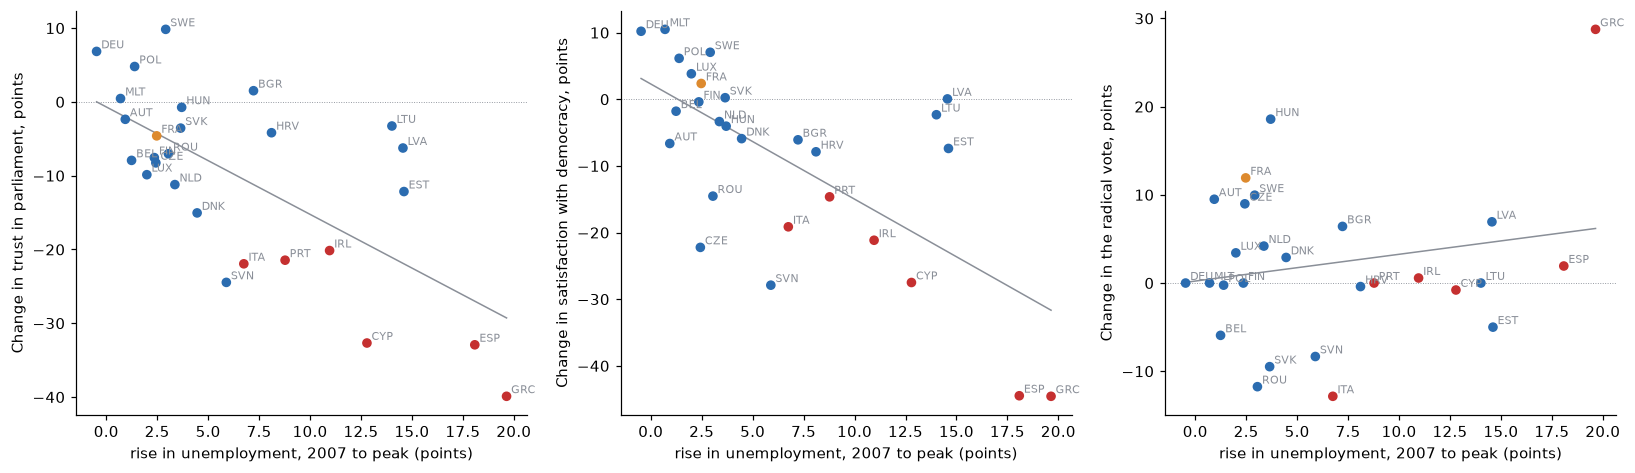

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (o, lab) in zip(axes, [('d_trust_parl', 'Change in trust in parliament, points'), ('d_swd', 'Change in satisfaction with democracy, points'), ('d_radical', 'Change in the radical vote, points')]):
    d = df[['u_rise', o]].dropna()
    colr = [RED if c in STRESS else (ORANGE if c == HELD_OUT else BLUE) for c in d.index]
    ax.scatter(d.u_rise, d[o], c=colr, s=28, zorder=3)
    for c, r in d.iterrows(): ax.annotate(c, (r.u_rise, r[o]), fontsize=7, xytext=(3, 2), textcoords='offset points', color=GREY)
    b, _ = fit_ols(d[o].to_numpy(), d[['u_rise']].to_numpy()); xs = np.linspace(d.u_rise.min(), d.u_rise.max(), 20); ax.plot(xs, b[0] + b[1] * xs, color=GREY, lw=1)
    ax.axhline(0, color=GREY, lw=0.6, ls=':'); ax.set_xlabel('rise in unemployment, 2007 to peak (points)'); ax.set_ylabel(lab)
plt.tight_layout(); plt.show()

In [7]:
# Robustness of the main trust result: drop one country at a time; later follow-up; other severity measures (exploratory, all reported)
d = df[['u_rise', 'd_trust_parl']].dropna()
loo = {c: fit_ols(d.drop(c).d_trust_parl.to_numpy(), d.drop(c)[['u_rise']].to_numpy())[0][1] for c in d.index}
lo_c, hi_c = min(loo, key=loo.get), max(loo, key=loo.get)
print(f"Trust in parliament, slope per point of unemployment: all countries {fit_ols(d.d_trust_parl.to_numpy(), d[['u_rise']].to_numpy())[0][1]:+.2f}; dropping one country at a time {loo[lo_c]:+.2f} (without {lo_c}) to {loo[hi_c]:+.2f} (without {hi_c}).")
late = design_b(late=True, outcomes={k: v for k, v in FAMILY.items() if k.startswith('d_trust') or k == 'd_swd'})
print('Follow-up 2014-15 instead of 2012-13 (has trust come back?):'); display(late.assign(**{'rank corr.': late.rho.round(2), 'p (perm.)': late.p.round(3), 'slope per point (90% range)': late.apply(lambda r: f"{r.slope:+.2f} ({r.lo:+.2f} to {r.hi:+.2f})", axis=1)})[['outcome', 'n', 'rank corr.', 'p (perm.)', 'slope per point (90% range)']].set_index('outcome'))
rows = []
for col, lab in [('u_rise', 'Unemployment rise (main)'), ('gdp_below_2007', 'GDP below 2007 level'), ('spread_peak_bp', 'Sovereign spread peak'), ('debt_jump', 'Debt jump'), ('bailout', 'Bailout programme'), ('esrb_months', 'ESRB crisis length (months)')]:
    row = {'severity measure': lab}
    for o in ['d_trust_parl', 'd_swd', 'd_radical', 'd_populist']:
        dd = df[[col, o]].dropna()
        if dd[col].nunique() < 2: row[LABEL[o]] = '–'; continue
        r, p = perm_p(dd[col], dd[o], B=4000); row[LABEL[o]] = f"{r:+.2f} (p {p:.3f}, n={len(dd)})"
    rows.append(row)
print('Other severity measures, rank correlation with each outcome (exploratory: 6 measures x 4 outcomes = 24 comparisons):'); display(pd.DataFrame(rows).set_index('severity measure'))

Trust in parliament, slope per point of unemployment: all countries -1.46; dropping one country at a time -1.63 (without LTU) to -1.24 (without GRC).


Follow-up 2014-15 instead of 2012-13 (has trust come back?):


,n,rank corr.,p (perm.),slope per point (90% range)
outcome,,,,
Trust in parliament,27,-0.45,0.020,-1.23 (-1.84 to -0.49)
Trust in government,27,-0.46,0.018,-1.06 (-1.70 to -0.35)
Trust in parties,27,-0.44,0.026,-0.65 (-1.02 to -0.20)
Satisfied with democracy,27,-0.39,0.048,-1.50 (-2.33 to -0.37)


Other severity measures, rank correlation with each outcome (exploratory: 6 measures x 4 outcomes = 24 comparisons):


,Trust in parliament,Satisfied with democracy,Radical vote (far right + far left),Populist vote
severity measure,,,,
Unemployment rise (main),"-0.57 (p 0.004, n=27)","-0.64 (p 0.001, n=27)","-0.00 (p 0.991, n=27)","-0.07 (p 0.720, n=27)"
GDP below 2007 level,"-0.53 (p 0.006, n=27)","-0.46 (p 0.016, n=27)","-0.07 (p 0.735, n=27)","-0.07 (p 0.747, n=27)"
Sovereign spread peak,"-0.33 (p 0.104, n=26)","-0.53 (p 0.004, n=26)","-0.11 (p 0.591, n=26)","-0.07 (p 0.716, n=26)"
Debt jump,"-0.73 (p 0.000, n=27)","-0.64 (p 0.001, n=27)","-0.14 (p 0.470, n=27)","-0.03 (p 0.881, n=27)"
Bailout programme,"-0.42 (p 0.032, n=27)","-0.49 (p 0.009, n=27)","+0.15 (p 0.485, n=27)","+0.06 (p 0.796, n=27)"
ESRB crisis length (months),"-0.38 (p 0.102, n=20)","-0.39 (p 0.092, n=20)","-0.02 (p 0.928, n=20)","-0.02 (p 0.926, n=20)"


**Reading section 3.** The trust result is the one the earlier notebook anticipated and it holds up: each extra point of unemployment goes with roughly one and a half points less trust in parliament and in government, about one point less trust in parties and nearly two points less satisfaction with democracy, without or with the controls, and the main comparison passes the Bonferroni correction. No single country drives it (Greece out lowers the slope but it stays far from zero). **The vote is different**: the radical and populist vote show no relationship with how much unemployment rose. That is not a statement that the crisis had no effect on the vote (see section 5, which has far more elections); it says that the *size of the unemployment rise* does not sort countries by how much their radical vote moved.

## 4. Through time: the path of the effect, and a panel check

**A. The path.** The same cross-country regression, repeated **wave by wave**: the change in trust since 2006–07 against the unemployment rise (final, 2007 to peak). If the crisis is what moves trust, the slope should start near zero before the crisis hit, grow as it did, and, if trust recovers, shrink again.

**B. A within-country check.** A panel of country and wave (2008–2016), with severity measured **as it had built up at each wave** (unemployment rise so far, GDP shortfall so far, spread so far) and **wave effects** that remove anything that moved all of Europe at once. The country effect is removed by measuring each outcome as the change from its own 2006–07 level. Ranges are wild cluster bootstrap by country (27 clusters).

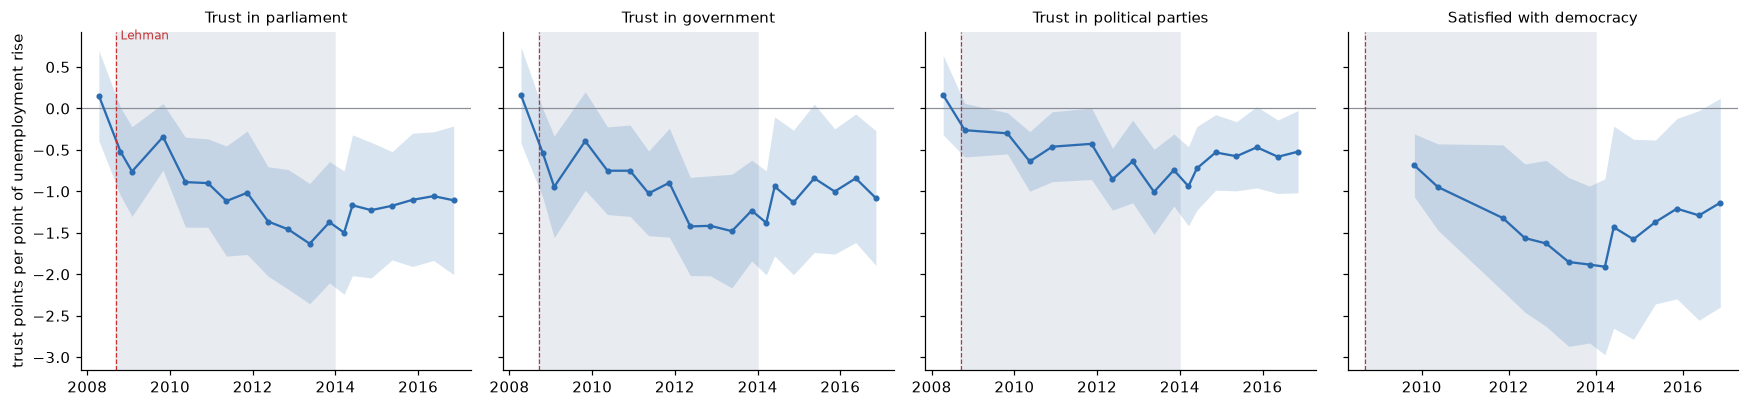

Trust in parliament: the slope is +0.16 in Apr 2008, reaches -1.63 in May 2013, and is -1.11 in Nov 2016: 68% of the trough is still there at the end of the window.


In [8]:
def cross_section_path(outcome_col, sev_col='u_rise', controls=False):
    base = window_mean(outcome_col, '2006-01-01', '2007-12-31')
    w = eb[(eb.fieldwork_median >= '2008-01-01') & (eb.fieldwork_median <= '2016-12-31')].copy()
    w['dy'] = w[outcome_col] - w.iso3.map(base)
    rows = []
    for za, g in w.groupby('za'):
        g = g.set_index('iso3').join(sev[[sev_col]]).dropna(subset=['dy', sev_col])
        if controls: g = g.join(df[['euro', 'log_income']]).join(base.rename('before')); g = g.dropna(subset=['before'])
        if len(g) < 20: continue
        X = g[[sev_col] + (['before', 'euro', 'log_income'] if controls else [])].to_numpy()
        b, se = fit_ols(g.dy.to_numpy(), X); c = t90(len(g) - X.shape[1] - 1)
        rows.append({'date': g.fieldwork_median.median(), 'n': len(g), 'slope': b[1], 'lo': b[1] - c * se[1], 'hi': b[1] + c * se[1]})
    return pd.DataFrame(rows)
paths = {k: cross_section_path(col) for k, (col, _) in SURVEY.items()}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (k, (col, label)) in zip(axes, SURVEY.items()):
    p = paths[k]
    ax.axvspan(LEHMAN, pd.Timestamp('2013-12-31'), color=LIGHT, zorder=0); ax.axhline(0, color=GREY, lw=0.8)
    ax.fill_between(p.date, p.lo, p.hi, color=BLUE, alpha=0.18, lw=0); ax.plot(p.date, p.slope, 'o-', color=BLUE, ms=3)
    ax.axvline(LEHMAN, color=RED, lw=0.8, ls='--'); ax.set_title(label, fontsize=10)
import matplotlib.dates as mdates
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].set_ylabel('trust points per point of unemployment rise'); axes[0].text(LEHMAN, axes[0].get_ylim()[1] * 0.9, ' Lehman', color=RED, fontsize=8)
plt.tight_layout(); plt.show()
pk = paths['trust_parl']; i_min = pk.slope.idxmin()
print(f"Trust in parliament: the slope is {pk.slope.iloc[0]:+.2f} in {pk.date.iloc[0]:%b %Y}, reaches {pk.slope.iloc[i_min]:+.2f} in {pk.date.iloc[i_min]:%b %Y}, and is {pk.slope.iloc[-1]:+.2f} in {pk.date.iloc[-1]:%b %Y}: {pk.slope.iloc[-1] / pk.slope.min():.0%} of the trough is still there at the end of the window.")

In [9]:
# Panel: severity so far at each wave, wave effects, country-clustered wild bootstrap
def severity_to_date(iso3, date):
    m = pd.Period(date, 'M'); q = pd.Period(date, 'Q') - 1
    u3 = U3[iso3].loc['2008-01':m]; ub = u_base[iso3]
    gq = G[iso3].loc['2008Q1':q]; sp = SPREAD[iso3].loc['2008-01':m]
    return {'u_peak': max(0.0, u3.max() - ub) if len(u3) else np.nan, 'u_now': u3.iloc[-1] - ub if len(u3) else np.nan,
            'gdp_worst': max(0.0, -(gq.min() / g_base[iso3] - 1) * 100) if len(gq) else np.nan,
            'spread_peak': max(0.0, sp.max()) / 100 if sp.notna().any() else np.nan}

def build_panel(col):
    base = window_mean(col, '2006-01-01', '2007-12-31')
    w = eb[(eb.fieldwork_median >= '2008-01-01') & (eb.fieldwork_median <= '2016-12-31')][['iso3', 'za', 'fieldwork_median', col]].dropna().copy()
    w['dy'] = w[col] - w.iso3.map(base); w['before'] = w.iso3.map(base)
    sv = pd.DataFrame([severity_to_date(r.iso3, r.fieldwork_median) for r in w.itertuples()], index=w.index)
    return pd.concat([w, sv], axis=1).dropna(subset=['dy', 'u_peak', 'u_now', 'gdp_worst'])

def panel_fit(pn, xcols, extra=('before',)):
    X = pd.concat([pn[list(xcols) + list(extra)], pd.get_dummies(pn.za, prefix='w', drop_first=True, dtype=float)], axis=1).astype(float)
    X.insert(0, 'const', 1.0); Xv, yv = X.to_numpy(), pn.dy.to_numpy()
    XtXi = np.linalg.pinv(Xv.T @ Xv); b = XtXi @ Xv.T @ yv; u = yv - Xv @ b
    _, inv = np.unique(pn.iso3.to_numpy(), return_inverse=True); Gc = inv.max() + 1
    D = np.zeros((len(yv), Gc)); D[np.arange(len(yv)), inv] = 1
    return {'X': X, 'Xv': Xv, 'y': yv, 'b': pd.Series(b, X.columns), 'u': u, 'inv': inv, 'D': D, 'XtXi': XtXi, 'G': Gc, 'pn': pn}

def wild(model, cols, B=999, seed=RNG_SEED, alpha=0.10):
    Xv, yv, u, XtXi, D, inv, Gc = model['Xv'], model['y'], model['u'], model['XtXi'], model['D'], model['inv'], model['G']
    idx = [list(model['X'].columns).index(c) for c in cols]; C = np.zeros((len(idx), Xv.shape[1]))
    for i, j in enumerate(idx): C[i, j] = 1.0
    n, k = Xv.shape; adj = Gc / (Gc - 1) * (n - 1) / (n - k); P = C @ XtXi; theta = C @ model['b'].to_numpy()
    se_of = lambda uv: np.sqrt(adj * ((D.T @ (Xv * uv[:, None]) @ P.T) ** 2).sum(axis=0)); se0 = se_of(u)
    rng = np.random.default_rng(seed); fitted = Xv @ model['b'].to_numpy(); T = np.empty((B, len(C)))
    for i in range(B):
        ys = fitted + rng.choice([-1.0, 1.0], size=Gc)[inv] * u; bs = XtXi @ (Xv.T @ ys)
        T[i] = (C @ bs - theta) / se_of(ys - Xv @ bs)
    qlo, qhi = np.nanquantile(T, [alpha / 2, 1 - alpha / 2], axis=0)
    return pd.DataFrame({'effect': theta, 'lo': theta - qhi * se0, 'hi': theta + (-qlo) * se0}, index=cols)

SPECS = {'Unemployment rise so far (peak)': ['u_peak'], 'Unemployment gap now': ['u_now'], 'Peak and gap together': ['u_peak', 'u_now'],
         'Unemployment, GDP and spread together (peaks)': ['u_peak', 'gdp_worst', 'spread_peak']}
panels = {k: build_panel(col) for k, (col, _) in SURVEY.items()}
rows = []
for k, (col, label) in SURVEY.items():
    for sname, xc in SPECS.items():
        pn = panels[k].dropna(subset=xc)
        m = panel_fit(pn, xc); r = wild(m, xc, B=499)
        rows.append({'outcome': label, 'specification': sname, 'n': len(pn), **{f'{c}': f"{r.effect[c]:+.2f} ({r.lo[c]:+.2f} to {r.hi[c]:+.2f})" for c in xc}})
panel_tab = pd.DataFrame(rows).fillna('')
print('Panel, effect on the change in the outcome since 2006-07, per unit of severity so far (points per point of unemployment; per % of GDP below the 2007 level; per 100 basis points of spread), 90% wild-bootstrap range:')
display(panel_tab.set_index(['outcome', 'specification']))

Panel, effect on the change in the outcome since 2006-07, per unit of severity so far (points per point of unemployment; per % of GDP below the 2007 level; per 100 basis points of spread), 90% wild-bootstrap range:


n                  u_peak                   u_now               gdp_worst             spread_peak
outcome                    specification                                                                                                                                     
Trust in parliament        Unemployment rise so far (peak)                512  -1.26 (-1.88 to -0.68)                                                                        
                           Unemployment gap now                           512                          -1.76 (-2.07 to -1.46)                                                
                           Peak and gap together                          512  +0.58 (-0.07 to +1.29)  -2.34 (-3.08 to -1.63)                                                
                           Unemployment, GDP and spread together (peaks)  493  -1.44 (-2.09 to -0.85)                          +0.63 (+0.02 to +1.39)  -0.80 (-1.39 to -0.28)
Trust in government        Unemployment rise so far (peak)                512  -1.11 (-1.71 to -0.61)                                                                        
                           Unemployment gap now                           512                          -1.59 (-1.86 to -1.35)                                                
                           Peak and gap together                          512  +0.52 (-0.54 to +1.57)  -2.10 (-3.20 to -1.09)                                                
                           Unemployment, GDP and spread together (peaks)  493  -1.45 (-2.24 to -0.72)                          +0.60 (-0.05 to +1.41)  -0.51 (-1.14 to +0.07)
Trust in political parties Unemployment rise so far (peak)                458  -0.73 (-1.13 to -0.42)                                                                        
                           Unemployment gap now                           458                          -1.00 (-1.20 to -0.81)                                                
                           Peak and gap together                          458  +0.26 (-0.12 to +0.63)  -1.27 (-1.69 to -0.84)                                                
                           Unemployment, GDP and spread together (peaks)  441  -0.94 (-1.59 to -0.36)                          +0.31 (-0.06 to +0.76)  -0.23 (-0.55 to +0.09)
Satisfied with democracy   Unemployment rise so far (peak)                375  -1.56 (-2.54 to -0.67)                                                                        
                           Unemployment gap now                           375                          -2.31 (-2.73 to -1.91)                                                
                           Peak and gap together                          375  +0.98 (+0.02 to +2.05)  -3.29 (-4.21 to -2.38)                                                
                           Unemployment, GDP and spread together (peaks)  361  -2.03 (-3.00 to -1.09)                          +1.34 (+0.56 to +2.23)  -1.32 (-2.26 to -0.47)

**Reading section 4.** The path is what a crisis effect should look like: no gap in 2008, a growing gap through 2009–2013, a trough in 2013, and **only partial recovery**: about two thirds of the trough is still there in 2016. The panel with severity as it built up gives the same size as the one-window cross-section. Two things in it are worth noticing. First, trust follows **how bad unemployment is now**, not how bad it got: with the peak and the current gap both in, the current gap carries the effect and the peak adds nothing, so trust recovers where unemployment fell back and stays low where it did not. Second, with unemployment, the GDP shortfall and the sovereign spread all in, **unemployment still carries the largest effect, the spread adds a separate effect** (about 0.8 points of trust in parliament and 1.3 of satisfaction with democracy per 100 basis points) and the GDP shortfall adds nothing (its coefficient is positive, a sign that it moves too closely with unemployment to be told apart).

## 5. The vote: all elections, not one per country

The cross-country comparison used one election per country. Here, **every pair of consecutive parliamentary elections** from 2001 on (140 pairs in 27 countries). The outcome is the change in the vote between the two; the regressor is the **change in unemployment** over the same stretch (average of the six months to each election). Period effects (2001–07, 2008–11, 2012–15, 2016 on) take out anything common to Europe in that period, and the years between the elections are a control. Ranges are wild cluster bootstrap by country.

Two further checks: **rises and falls separately** (a crisis effect should show on rises, not mirror on falls), and the **banking-crisis timing** from the ESRB database: whether the pair of elections straddles the start of the country's systemic crisis, which is the comparison in the literature that found far-right gains after financial crises.

In [10]:
pairs = []
for iso, g in rp.groupby('iso3'):
    if iso not in U.columns: continue
    g = g.sort_values('election_date').reset_index(drop=True)
    for i in range(1, len(g)):
        a, b = g.election_date[i - 1], g.election_date[i]
        if a < pd.Timestamp('2001-01-01'): continue
        ua = U[iso].loc[pd.Period(a, 'M') - 5:pd.Period(a, 'M')].mean(); ub = U[iso].loc[pd.Period(b, 'M') - 5:pd.Period(b, 'M')].mean()
        if np.isnan(ua) or np.isnan(ub): continue
        cs = gfc.start_m.get(iso, None)
        comp = bool(g.compulsory_voting[i] or g.compulsory_voting[i - 1]) if pd.notna(g.compulsory_voting[i]) and pd.notna(g.compulsory_voting[i - 1]) else False
        pairs.append({'iso3': iso, 'prev': a, 'date': b, 'years': (b - a).days / 365.25, 'dU': ub - ua,
                      'crisis_pair': float(cs is not None and a < pd.Period(cs, 'M').to_timestamp() <= b),
                      'd_radical': g.radical_pct[i] - g.radical_pct[i - 1], 'd_farright': g.farright_pct[i] - g.farright_pct[i - 1], 'd_farleft': g.farleft_pct[i] - g.farleft_pct[i - 1],
                      'd_populist': g.populist_pct[i] - g.populist_pct[i - 1], 'd_enp': g.effective_parties[i] - g.effective_parties[i - 1],
                      'd_turnout': np.nan if comp else g.turnout_pct[i] - g.turnout_pct[i - 1]})
P = pd.DataFrame(pairs)
P['period'] = pd.cut(P.date.dt.year, [2000, 2007, 2011, 2015, 2100], labels=['2001-07', '2008-11', '2012-15', '2016+']).astype(str)
P['dU_up'] = P.dU.clip(lower=0); P['dU_down'] = P.dU.clip(upper=0)
print(f"{len(P)} pairs of consecutive elections in {P.iso3.nunique()} countries; {int(P.crisis_pair.sum())} pairs straddle a crisis start (ESRB). Unemployment change between elections: median {P.dU.median():+.1f}, range {P.dU.min():+.1f} to {P.dU.max():+.1f} points.")

def election_fit(ycol, xcols):
    pn = P.dropna(subset=[ycol] + xcols).copy()
    X = pd.concat([pn[xcols + ['years']], pd.get_dummies(pn.period, prefix='p', drop_first=True, dtype=float)], axis=1).astype(float); X.insert(0, 'const', 1.0)
    Xv, yv = X.to_numpy(), pn[ycol].to_numpy(); XtXi = np.linalg.pinv(Xv.T @ Xv); b = XtXi @ Xv.T @ yv; u = yv - Xv @ b
    _, inv = np.unique(pn.iso3.to_numpy(), return_inverse=True); Gc = inv.max() + 1; D = np.zeros((len(yv), Gc)); D[np.arange(len(yv)), inv] = 1
    return {'X': X, 'Xv': Xv, 'y': yv, 'b': pd.Series(b, X.columns), 'u': u, 'inv': inv, 'D': D, 'XtXi': XtXi, 'G': Gc, 'pn': pn}
ELEC_OUT = {'d_radical': 'Radical vote', 'd_farright': 'Far-right vote', 'd_farleft': 'Far-left vote', 'd_populist': 'Populist vote', 'd_enp': 'Effective number of parties', 'd_turnout': 'Turnout (pp)'}
rows = []
for yc, lab in ELEC_OUT.items():
    row = {'outcome': lab}
    for sname, xc in [('per point of unemployment change', ['dU']), ('rises', ['dU_up', 'dU_down']), ('crisis pair', ['dU', 'crisis_pair'])]:
        m = election_fit(yc, xc); r = wild(m, xc, B=499)
        row['n'] = len(m['pn'])
        for c in xc: row[f'{sname}: {c}'] = f"{r.effect[c]:+.2f} ({r.lo[c]:+.2f} to {r.hi[c]:+.2f})"
    rows.append(row)
elec_tab = pd.DataFrame(rows).set_index('outcome')
display(elec_tab[['n', 'per point of unemployment change: dU', 'rises: dU_up', 'rises: dU_down', 'crisis pair: dU', 'crisis pair: crisis_pair']])

140 pairs of consecutive elections in 27 countries; 20 pairs straddle a crisis start (ESRB). Unemployment change between elections: median -0.5, range -8.9 to +12.9 points.


,n,per point of unemployment change: dU,rises: dU_up,rises: dU_down,crisis pair: dU,crisis pair: crisis_pair
outcome,,,,,,
Radical vote,140,+0.07 (-0.59 to +0.67),+0.26 (-0.37 to +0.84),-0.15 (-0.95 to +0.61),+0.03 (-0.57 to +0.55),+1.36 (-2.46 to +4.58)
Far-right vote,140,-0.08 (-0.39 to +0.20),+0.14 (-0.26 to +0.53),-0.34 (-0.80 to +0.11),-0.14 (-0.44 to +0.13),+1.86 (-1.13 to +4.58)
Far-left vote,140,+0.15 (-0.23 to +0.50),+0.11 (-0.22 to +0.42),+0.19 (-0.22 to +0.60),+0.17 (-0.18 to +0.48),-0.50 (-2.57 to +1.44)
Populist vote,140,-0.09 (-0.64 to +0.45),-0.47 (-1.63 to +0.56),+0.35 (-0.35 to +1.04),-0.06 (-0.59 to +0.45),-1.02 (-5.68 to +3.31)
Effective number of parties,132,+0.01 (-0.10 to +0.12),+0.02 (-0.19 to +0.23),+0.00 (-0.09 to +0.08),-0.00 (-0.10 to +0.09),+0.42 (-0.20 to +1.12)
Turnout (pp),106,+0.17 (-0.23 to +0.58),+0.15 (-0.35 to +0.66),+0.20 (-0.66 to +1.02),+0.22 (-0.16 to +0.65),-1.98 (-5.04 to +0.92)


**Reading section 5.** With 140 election pairs instead of 27, the verdict on the radical vote is firmer: **no detectable effect of the unemployment change**, on the far right, the far left, the radical total or the populist vote. The ranges are narrow enough to rule out effects of more than about 0.6 points of radical vote per point of unemployment, and about 0.4 points for the far right alone. The rises-only split and the banking-crisis timing do not change that: the far-right gain around the start of a systemic crisis (last column) is positive but its range is wide and includes zero. So the crisis moved trust a great deal and the radical vote very little *in this measurement*; the limits (what PopuList counts as radical, parties inside alliances, coarse timing) are listed at the end.

## 6. Where was the effect concentrated?

The earlier notebook found that the trust result was mostly a story of the **older member states** (inside them the link between unemployment and trust is steep, inside the 2004-and-later members weak). This repeats it for the main trust outcome with proper ranges, and adds the **euro** and **bailout** splits. Each row is the slope per point of unemployment inside the group (resampled-country 90% range); the last column tests whether the slopes differ.

In [11]:
def group_slopes(o, split_col, labels):
    d = df[['u_rise', o, split_col]].dropna(); rows = []
    for v, lab in labels.items():
        g = d[d[split_col] == v]
        if len(g) < 6 or g.u_rise.nunique() < 4: rows.append({'group': lab, 'n': len(g), 'slope': np.nan}); continue
        b, _ = fit_ols(g[o].to_numpy(), g[['u_rise']].to_numpy()); lo, hi = boot_slope(g, o, ['u_rise'], B=2000)
        rows.append({'group': lab, 'n': len(g), 'slope': b[1], 'lo': lo, 'hi': hi, 'mean u_rise': g.u_rise.mean()})
    X = np.column_stack([d.u_rise, d[split_col], d.u_rise * d[split_col]]); b, se = fit_ols(d[o].to_numpy(), X)
    return pd.DataFrame(rows), b[3], se[3]
rows = []
for o in ['d_trust_parl', 'd_swd']:
    for split_col, labels, nm in [('new_member', {0: 'joined before 2004', 1: 'joined 2004 or later'}, 'EU membership'), ('euro', {1: 'euro area (2008)', 0: 'outside the euro'}, 'euro'), ('bailout', {1: 'had a programme', 0: 'no programme'}, 'bailout')]:
        t, bi, sei = group_slopes(o, split_col, labels)
        for k_, (_, r) in enumerate(t.iterrows()):
            rows.append({'outcome': LABEL[o], 'split': nm, 'group': r['group'], 'n': r['n'],
                         'slope per point (90% range)': f"{r['slope']:+.2f} ({r['lo']:+.2f} to {r['hi']:+.2f})" if pd.notna(r['slope']) else 'too few',
                         'mean unemployment rise': round(r.get('mean u_rise', np.nan), 1), 'difference between groups': f"{bi:+.2f} (z = {bi / sei:+.1f})" if k_ == 0 else ''})
display(pd.DataFrame(rows).set_index(['outcome', 'split', 'group']))

n slope per point (90% range)  mean unemployment rise difference between groups
outcome                  split         group                                                                                                 
Trust in parliament      EU membership joined before 2004    14      -1.97 (-2.47 to -1.68)                     6.0          +1.14 (z = +1.8)
                                       joined 2004 or later  13      -0.82 (-1.88 to -0.08)                     7.1                          
                         euro          euro area (2008)      13      -1.86 (-2.50 to -1.58)                     6.3          -0.92 (z = -1.4)
                                       outside the euro      14      -0.95 (-2.01 to -0.18)                     6.7                          
                         bailout       had a programme        8      -1.83 (-2.43 to -0.87)                    11.4          -1.18 (z = -1.7)
                                       no programme          19      -0.65 (-1.88 to -0.11)                     4.4                          
Satisfied with democracy EU membership joined before 2004    14      -2.64 (-2.92 to -2.31)                     6.0          +2.24 (z = +2.8)
                                       joined 2004 or later  13      -0.40 (-1.62 to +0.74)                     7.1                          
                         euro          euro area (2008)      13      -2.56 (-2.98 to -2.25)                     6.3          -1.97 (z = -2.7)
                                       outside the euro      14      -0.59 (-1.75 to +0.40)                     6.7                          
                         bailout       had a programme        8      -1.90 (-2.91 to -0.18)                    11.4          -1.00 (z = -1.0)
                                       no programme          19      -0.90 (-2.74 to -0.30)                     4.4

**Reading section 6.** The slope is steeper in the **older member states** and in the **euro area** than in the countries that joined later or stayed out of the euro, and steeper where there was a **bailout programme**. For trust in parliament the differences are suggestive (z between 1.4 and 1.8); for satisfaction with democracy they are clearer (z about 2.7 to 2.8 for membership and the euro). The three splits overlap heavily (the bailout countries are nearly all older members and euro members), so they cannot be told apart.

### Is the relationship a straight line?

Section 7 will show that a model fitted **without** the six stress countries predicts them in the right order but much too mildly. That suggests the link between unemployment and trust is steeper at the top than a single line says. This asks it directly: the slope among the 21 countries outside the stress group, a quadratic term, and whether a quadratic predicts better out of sample (leave one country out).

In [12]:
def loo_r2(d, o, cols):
    pred, base = [], []
    for c in d.index:
        tr = d.drop(c); bb, _ = fit_ols(tr[o].to_numpy(), tr[cols].to_numpy())
        pred.append(bb[0] + float((bb[1:] * d.loc[c, cols].to_numpy(float)).sum())); base.append(tr[o].mean())
    pred, base = np.array(pred), np.array(base)
    return 1 - ((d[o].to_numpy() - pred) ** 2).sum() / ((d[o].to_numpy() - base) ** 2).sum()
rows = []
for o in ['d_trust_parl', 'd_trust_gov', 'd_trust_parties', 'd_swd']:
    d = df[['u_rise', o]].dropna().copy(); d['u2'] = d.u_rise ** 2
    b, se = fit_ols(d[o].to_numpy(), d[['u_rise', 'u2']].to_numpy())
    rest = d.drop([c for c in STRESS if c in d.index]); br, _ = fit_ols(rest[o].to_numpy(), rest[['u_rise']].to_numpy()); lo, hi = boot_slope(rest, o, ['u_rise'], B=3000); r_, p_ = perm_p(rest.u_rise, rest[o], B=4000)
    ball, _ = fit_ols(d[o].to_numpy(), d[['u_rise']].to_numpy())
    rows.append({'outcome': LABEL[o], 'slope, all 27': ball[1], 'slope, 21 outside the stress group (90% range)': f"{br[1]:+.2f} ({lo:+.2f} to {hi:+.2f}), rank corr. {r_:+.2f} (p {p_:.3f})",
                 'quadratic term (z)': f"{b[2]:+.3f} ({b[2] / se[2]:+.1f})", 'out-of-sample R2, line': loo_r2(d, o, ['u_rise']), 'out-of-sample R2, quadratic': loo_r2(d, o, ['u_rise', 'u2'])})
nl = pd.DataFrame(rows).set_index('outcome'); display(nl.round(2))

,"slope, all 27","slope, 21 outside the stress group (90% range)",quadratic term (z),"out-of-sample R2, line","out-of-sample R2, quadratic"
outcome,,,,,
Trust in parliament,-1.46,"-0.43 (-1.04 to -0.02), rank corr. -0.31 (p 0.170)",-0.012 (-0.1),0.39,0.31
Trust in government,-1.39,"-0.51 (-1.20 to +0.02), rank corr. -0.31 (p 0.165)",-0.015 (-0.2),0.40,0.36
Trust in parties,-0.81,"-0.19 (-0.54 to +0.07), rank corr. -0.28 (p 0.210)",-0.012 (-0.3),0.29,0.24
Satisfied with democracy,-1.73,"-0.48 (-1.57 to +0.04), rank corr. -0.50 (p 0.024)",-0.031 (-0.3),0.37,0.30


**Reading the table.** Outside the stress group the slope is a third to a half of the all-country slope, and for trust in parliament, government and parties the link is weak and not clearly different from zero (satisfaction with democracy keeps a clearer one). The line through all 27 countries is therefore **largely a contrast between the stress countries and the rest**, not a smooth dose-response that holds across the whole range. The quadratic term is negative (a little more decline at the top) but tiny and indistinguishable from zero, and the quadratic does not predict better out of sample (R² 0.24 to 0.36 against 0.29 to 0.40 for the straight line); with 27 countries the data cannot tell a gentle curve from a line, so the contrast is best read as a **difference between groups of countries**, not as a fitted curve. For a stress test this is the main caveat of the section: the reading for a given unemployment rise is trustworthy as a description of *what happened in this crisis*, and extrapolating it as a smooth rule to a moderate rise in a country with no bailout overstates what the data show.

## 7. The tests that matter for a stress test

A fit across 27 countries says the pattern exists. A *stress test* needs more: **can the pattern predict a country it has not seen?** Four tests.

1. **Hold out the six hardest-hit countries** (Greece, Ireland, Portugal, Spain, Italy, Cyprus: the reference episodes) and predict them from the other 21. This is the hardest test, because their unemployment rises sit at or beyond the top of what the other 21 show (an extrapolation).
2. **Hold out France**, the case study, and compare the prediction with what happened.
3. **Leave one country out at a time** (all 27), scored against "no change" and against "the average country" with a calibrated range for a single country.
4. **A placebo before the crisis**: the same regression for 2003–04 to 2006–07, a period with no financial crisis. If the pattern is a feature of how unemployment relates to trust in *any* period it should appear there too.

In [13]:
def loo_predictions(o, sev_col='u_rise', exclude=()):
    d = df[[sev_col, o]].dropna(); rows = []
    for c in d.index:
        tr = d.drop(list(set([c]) | set(exclude)) if exclude else [c])
        b, _ = fit_ols(tr[o].to_numpy(), tr[[sev_col]].to_numpy())
        resid = tr[o].to_numpy() - (b[0] + b[1] * tr[sev_col].to_numpy())
        rows.append({'iso3': c, 'sev': d.at[c, sev_col], 'actual': d.at[c, o], 'predicted': b[0] + b[1] * d.at[c, sev_col], 'mean_baseline': tr[o].mean(), 'train_max': tr[sev_col].max(), 'resid_sd': resid.std(ddof=2)})
    return pd.DataFrame(rows).set_index('iso3')

# 1. hold out the six stress countries
rows = []
for o in ['d_trust_parl', 'd_trust_gov', 'd_trust_parties', 'd_swd', 'd_radical']:
    d = df[['u_rise', o]].dropna(); tr = d.drop([c for c in STRESS if c in d.index]); te = d.loc[[c for c in STRESS if c in d.index]]
    b, _ = fit_ols(tr[o].to_numpy(), tr[['u_rise']].to_numpy()); pred = b[0] + b[1] * te.u_rise
    rows.append({'outcome': LABEL[o], 'trained on': len(tr), 'slope': b[1], 'MAE model': (te[o] - pred).abs().mean(), 'MAE "no change"': te[o].abs().mean(), 'MAE training mean': (te[o] - tr[o].mean()).abs().mean(),
                 'corr(pred, actual)': float(np.corrcoef(pred, te[o])[0, 1])})
hold6 = pd.DataFrame(rows).set_index('outcome')
print(f"Held out: {', '.join(STRESS)}. The training countries' largest unemployment rise is {df.drop(STRESS).u_rise.max():.1f}; the held-out ones range {df.loc[STRESS].u_rise.min():.1f} to {df.loc[STRESS].u_rise.max():.1f}.")
display(hold6.round(2))
dd = df[['u_rise', 'd_trust_parl']].dropna(); trn = dd.drop(STRESS); bb, _ = fit_ols(trn.d_trust_parl.to_numpy(), trn[['u_rise']].to_numpy())
tab = dd.loc[STRESS].assign(predicted=lambda t: bb[0] + bb[1] * t.u_rise)[['u_rise', 'd_trust_parl', 'predicted']].rename(columns={'d_trust_parl': 'actual change in trust in parliament'}); display(tab.round(1))

Held out: GRC, IRL, PRT, ESP, ITA, CYP. The training countries' largest unemployment rise is 14.6; the held-out ones range 6.8 to 19.6.


,trained on,slope,MAE model,"MAE ""no change""",MAE training mean,"corr(pred, actual)"
outcome,,,,,,
Trust in parliament,21,-0.43,19.66,28.17,23.17,0.89
Trust in government,21,-0.51,16.77,25.94,20.94,0.87
Trust in parties,21,-0.19,11.87,13.12,13.43,0.72
Satisfied with democracy,21,-0.48,21.37,28.58,25.24,0.96
Radical vote (far right + far left),21,-0.14,8.14,7.48,7.97,-0.80


,u_rise,actual change in trust in parliament,predicted
iso3,,,
GRC,19.6,-39.9,-11.5
IRL,11.0,-20.1,-7.7
PRT,8.8,-21.5,-6.8
ESP,18.1,-32.9,-10.8
ITA,6.8,-21.9,-5.9
CYP,12.8,-32.7,-8.5


In [14]:
# 2. France, and 3. leave one country out for every outcome
rows = []; allloo = {}
def conformal_q(scores, level=0.90):
    n = len(scores); return np.sort(scores)[min(n, int(np.ceil((n + 1) * level))) - 1]
for o in FAMILY:
    lp = loo_predictions(o); allloo[o] = lp
    err = (lp.actual - lp.predicted).abs(); errz = lp.actual.abs(); errm = (lp.actual - lp.mean_baseline).abs()
    # fair conformal coverage: half-width from the other countries' errors
    cover = [float(err[c] <= conformal_q(err.drop(c).to_numpy())) for c in lp.index]
    ss_res = ((lp.actual - lp.predicted) ** 2).sum(); ss_tot = ((lp.actual - lp.mean_baseline) ** 2).sum()
    fr = lp.loc[HELD_OUT] if HELD_OUT in lp.index else None
    rows.append({'outcome': LABEL[o], 'n': len(lp), 'MAE model': err.mean(), 'MAE "no change"': errz.mean(), 'MAE country average': errm.mean(), 'out-of-sample R2': 1 - ss_res / ss_tot,
                 'conformal half-width': conformal_q(err.to_numpy()), 'conformal coverage': np.mean(cover),
                 'France actual': fr.actual if fr is not None else np.nan, 'France predicted': fr.predicted if fr is not None else np.nan})
loo_tab = pd.DataFrame(rows).set_index('outcome')
loo_tab['model beats no change'] = loo_tab['MAE model'] < loo_tab['MAE "no change"']; loo_tab['model beats country average'] = loo_tab['MAE model'] < loo_tab['MAE country average']
display(loo_tab.round(2))
print(f"Leave-one-country-out: the model beats 'no change' for {int(loo_tab['model beats no change'].sum())} of {len(loo_tab)} outcomes and beats 'the average country' for {int(loo_tab['model beats country average'].sum())}. For the four survey outcomes the out-of-sample R2 is {loo_tab.loc[[LABEL[k] for k in ['d_trust_parl', 'd_trust_gov', 'd_trust_parties', 'd_swd']], 'out-of-sample R2'].min():.2f} to {loo_tab.loc[[LABEL[k] for k in ['d_trust_parl', 'd_trust_gov', 'd_trust_parties', 'd_swd']], 'out-of-sample R2'].max():.2f}; for the radical vote {loo_tab.loc[LABEL['d_radical'], 'out-of-sample R2']:.2f}.")

,n,MAE model,"MAE ""no change""",MAE country average,out-of-sample R2,conformal half-width,conformal coverage,France actual,France predicted,model beats no change,model beats country average
outcome,,,,,,,,,,,
Trust in parliament,27,8.33,11.89,10.03,0.39,17.62,0.93,-4.60,-4.27,True,True
Radical vote (far right + far left),27,7.30,6.25,6.72,-0.14,18.07,0.93,11.92,0.32,False,False
Populist vote,27,9.35,9.18,8.99,-0.11,26.17,0.93,9.31,5.19,False,False
Trust in government,27,7.62,11.03,10.13,0.40,18.80,0.93,-2.21,-4.18,True,True
Trust in parties,27,5.76,6.35,6.60,0.29,12.80,0.93,0.51,0.59,True,True
Satisfied with democracy,27,9.30,11.94,11.97,0.37,21.86,0.93,2.37,-2.24,True,True
Far-right vote,27,6.17,5.23,5.87,-0.10,17.69,0.93,9.31,0.18,False,False
Far-left vote,27,1.94,1.38,1.78,-0.17,4.56,0.93,2.61,0.15,False,False
Effective number of parties,25,1.03,0.96,0.93,-0.26,3.52,0.92,NaN,NaN,False,False


Leave-one-country-out: the model beats 'no change' for 5 of 10 outcomes and beats 'the average country' for 4. For the four survey outcomes the out-of-sample R2 is 0.29 to 0.40; for the radical vote -0.14.


In [15]:
# 4. Placebo: 2003-04 to 2006-07, before the crisis
def pre_change(col, a1, b1_, a2, b2):
    return window_mean(col, a2, b2) - window_mean(col, a1, b1_)
u_pre = (U.loc['2006-01':'2007-12'].mean() - U.loc['2003-01':'2004-12'].mean())
rows = []
for k, (col, label) in SURVEY.items():
    dy = pre_change(col, '2003-01-01', '2004-12-31', '2006-01-01', '2007-12-31')
    d = pd.DataFrame({'u': u_pre, 'dy': dy}).dropna()
    if len(d) < 10: continue
    r, p = perm_p(d.u, d.dy, B=4000); b, _ = fit_ols(d.dy.to_numpy(), d[['u']].to_numpy()); lo, hi = boot_slope(d, 'dy', ['u'], B=2000)
    d2 = df[['u_rise', f'd_{k}']].dropna(); r2, _ = perm_p(d2.u_rise, d2[f'd_{k}'], B=100)
    rows.append({'outcome': label, 'n': len(d), 'placebo rank corr.': round(r, 2), 'placebo p': round(p, 3), 'placebo slope (90% range)': f"{b[1]:+.2f} ({lo:+.2f} to {hi:+.2f})", 'crisis rank corr.': round(r2, 2)})
placebo = pd.DataFrame(rows).set_index('outcome'); display(placebo)
print(f"Unemployment changed by {u_pre.min():+.1f} to {u_pre.max():+.1f} points across countries between 2003-04 and 2006-07 (against {sev.u_rise.min():+.1f} to {sev.u_rise.max():+.1f} in the crisis): a much smaller range.")

,n,placebo rank corr.,placebo p,placebo slope (90% range),crisis rank corr.
outcome,,,,,
Trust in parliament,27,-0.11,0.609,-0.22 (-1.13 to +0.73),-0.57
Trust in government,27,-0.01,0.981,-0.13 (-1.37 to +1.15),-0.58
Trust in political parties,27,0.11,0.602,+0.36 (-0.28 to +1.01),-0.54
Satisfied with democracy,27,-0.22,0.277,-0.18 (-1.11 to +0.83),-0.64


Unemployment changed by -7.7 to +1.5 points across countries between 2003-04 and 2006-07 (against -0.5 to +19.6 in the crisis): a much smaller range.


**Reading section 7.** Read the four tests together. (1) With the six hardest-hit countries held out, the model **gets their order right** (the correlation between predicted and actual is 0.7 to 0.96 for the survey outcomes) and does better than "no change", but it predicts only about a quarter to a third of the fall: trained on the 21 milder cases the slope is about −0.2 to −0.5 per point, against −0.8 to −1.7 over all 27. The stress countries are a different regime, as section 6b found. (2) France, a moderate case, is predicted for trust in parliament almost exactly; the radical vote is not (France's rose by 12 points with an unemployment rise of 2.5). (3) Leaving one country out at a time, the model beats both "no change" and "the average country" for the four survey outcomes, with an out-of-sample R² of about 0.3 to 0.4; for the vote it beats neither, as there is nothing in it to predict. (4) Before the crisis the same relationship is not there (rank correlations near zero, p above 0.27), with a far smaller range of unemployment changes: the pattern belongs to the crisis, not to a general link between unemployment and trust.

## 8. The reference episodes, one by one

The path of trust in parliament in the six stress countries and France, against the median of the other countries, with the unemployment path underneath. A scale for what "severe" looked like, and a reminder that these were also political crises (Greek elections of 2012, the Italian technocratic government of 2011, Cypriot bank resolution of 2013) that the model does not separate from the economic hit.

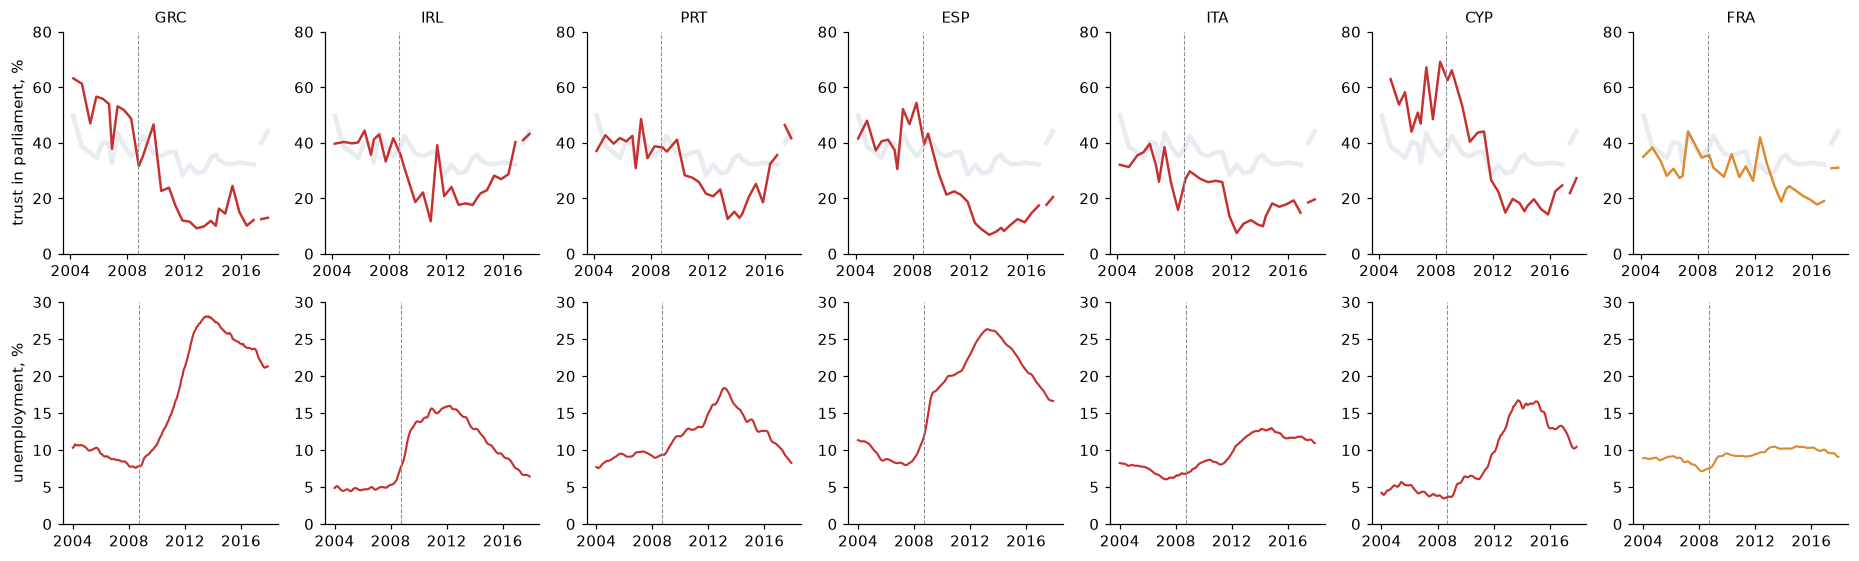

,u_rise,gdp_below_2007,spread_peak_bp,debt_jump,bailout,esrb_start,d_trust_parl,d_trust_gov,d_swd,d_radical,d_populist
iso3,,,,,,,,,,,
GRC,19.6,27.3,2739.0,75.8,1,2010-05,-39.9,-33.0,-44.6,28.8,21.5
IRL,11.0,11.1,971.0,93.8,1,2008-09,-20.1,-19.2,-21.2,0.6,3.0
PRT,8.8,8.7,1203.0,58.1,1,2008-10,-21.5,-19.5,-14.6,0.0,0.0
ESP,18.1,7.8,555.0,64.3,1,2009-03,-32.9,-33.5,-44.5,1.9,0.0
ITA,6.8,8.8,519.0,28.5,0,2011-08,-21.9,-17.4,-19.1,-12.8,25.1
CYP,12.8,7.8,580.0,52.6,1,2011-06,-32.7,-33.0,-27.5,-0.8,0.0
FRA,2.5,2.9,154.0,29.1,0,2008-04,-4.6,-2.2,2.4,11.9,9.3


In [16]:
fig, axes = plt.subplots(2, 7, figsize=(17, 5.2), sharex='row')
_o = eb[~eb.iso3.isin(STRESS + [HELD_OUT])]
others = _o.groupby('za').agg(d=('fieldwork_median', 'median'), v=('trust_parl_pct', 'median')).set_index('d').v.sort_index()
for j, c in enumerate(STRESS + [HELD_OUT]):
    ax = axes[0, j]; d = eb[(eb.iso3 == c) & (eb.fieldwork_median >= '2004-01-01') & (eb.fieldwork_median <= '2017-12-31')].sort_values('fieldwork_median')
    ax.plot(others[(others.index >= '2004-01-01') & (others.index <= '2017-12-31')].index, others[(others.index >= '2004-01-01') & (others.index <= '2017-12-31')].values, color=LIGHT, lw=3, label='median, other countries')
    ax.plot(d.fieldwork_median, d.trust_parl_pct, color=RED if c in STRESS else ORANGE, lw=1.6); ax.axvline(LEHMAN, color=GREY, lw=0.7, ls='--'); ax.set_title(c, fontsize=10); ax.set_ylim(0, 80)
    ax2 = axes[1, j]; u_ = U3[c].loc['2004-01':'2017-12']; ax2.plot(u_.index.to_timestamp(), u_.values, color=RED if c in STRESS else ORANGE, lw=1.4); ax2.axvline(LEHMAN, color=GREY, lw=0.7, ls='--'); ax2.set_ylim(0, 30)
import matplotlib.dates as mdates
for ax in axes.ravel():
    ax.xaxis.set_major_locator(mdates.YearLocator(4)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0, 0].set_ylabel('trust in parliament, %'); axes[1, 0].set_ylabel('unemployment, %')
plt.tight_layout(); plt.show()
cs = df.loc[STRESS + [HELD_OUT], ['u_rise', 'gdp_below_2007', 'spread_peak_bp', 'debt_jump', 'bailout', 'esrb_start', 'd_trust_parl', 'd_trust_gov', 'd_swd', 'd_radical', 'd_populist']].round(1)
display(cs)

## 9. A reading for France

France was moderately hit: unemployment rose by 2.5 points from 2007 to its peak, output fell 2.9% below its 2007 level at the worst, no bailout. The readings below ask *what if* a crisis had hit France with a given **rise in unemployment**, using the cross-country slope estimated **without France** (with its resampled-country 90% range), and add the single-episode half-width from the leave-one-country-out test. They are for the 2012–13 follow-up. France's levels today are from Eurobarometer 105.2 (spring 2026).

The GDP and spread measures cannot be added to the unemployment reading: they move with it (rank correlation above 0.6) and the panel showed they add little once unemployment is in. They are reported on their own, as the slope per unit, so a dashboard can offer them as alternative sliders, never as a sum.

In [17]:
FR_NOW = {'d_trust_parl': 23, 'd_trust_gov': 21, 'd_trust_parties': 12, 'd_swd': 56}
rows = []
for o in ['d_trust_parl', 'd_trust_gov', 'd_trust_parties', 'd_swd', 'd_radical']:
    d = df.drop(HELD_OUT)[['u_rise', o]].dropna(); b, _ = fit_ols(d[o].to_numpy(), d[['u_rise']].to_numpy()); lo, hi = boot_slope(d, o, ['u_rise'], B=4000)
    q = float(loo_tab.loc[LABEL[o], 'conformal half-width'])
    for dU in (3, 6, 10, 15):
        rows.append({'outcome': LABEL[o], 'unemployment rise (points)': dU, 'change': b[0] + b[1] * dU, 'lo': b[0] + min(lo * dU, hi * dU), 'hi': b[0] + max(lo * dU, hi * dU), 'one-country half-width': q,
                     'slope per point': b[1], 'slope_lo': lo, 'slope_hi': hi, 'observed range of rises': f"{d.u_rise.min():.1f} to {d.u_rise.max():.1f}"})
reading = pd.DataFrame(rows)
fr_tab = reading.assign(**{'change (90% range of the average effect)': reading.apply(lambda r: f"{r.change:+.1f} ({r.lo:+.1f} to {r.hi:+.1f})", axis=1), 'add for one country': reading['one-country half-width'].map(lambda v: f"±{v:.0f}")})
display(fr_tab.pivot(index='outcome', columns='unemployment rise (points)', values='change (90% range of the average effect)')[[3, 6, 10, 15]])
display(fr_tab.drop_duplicates('outcome')[['outcome', 'slope per point', 'add for one country']].set_index('outcome').round(2))
rows2 = []
for sc, lab in [('gdp_below_2007', 'GDP below 2007 level, per % '), ('spread_peak_bp', 'sovereign spread, per 100 bp'), ('debt_jump', 'debt jump, per point of GDP')]:
    d = df.drop(HELD_OUT)[[sc, 'd_trust_parl']].dropna(); scale = 100 if sc == 'spread_peak_bp' else 1
    b, _ = fit_ols(d.d_trust_parl.to_numpy(), (d[[sc]] / scale).to_numpy()); lo, hi = boot_slope(d.assign(**{sc: d[sc] / scale}), 'd_trust_parl', [sc], B=2000)
    rows2.append({'alternative severity measure': lab, 'trust in parliament, change per unit (90% range)': f"{b[1]:+.2f} ({lo:+.2f} to {hi:+.2f})", 'n': len(d)})
display(pd.DataFrame(rows2).set_index('alternative severity measure'))

unemployment rise (points),3,6,10,15
outcome,,,,
Radical vote (far right + far left),+0.5 (-1.5 to +2.3),+1.6 (-2.5 to +5.2),+3.0 (-3.8 to +9.1),+4.8 (-5.5 to +13.9)
Satisfied with democracy,-3.1 (-5.2 to -0.3),-8.3 (-12.4 to -2.6),-15.1 (-22.1 to -5.7),-23.6 (-34.1 to -9.5)
Trust in government,-4.9 (-6.3 to -3.2),-9.0 (-11.9 to -5.6),-14.5 (-19.3 to -8.8),-21.4 (-28.6 to -12.8)
Trust in parliament,-5.0 (-6.7 to -3.0),-9.4 (-12.6 to -5.4),-15.2 (-20.6 to -8.5),-22.5 (-30.6 to -12.5)
Trust in parties,+0.2 (-0.9 to +1.4),-2.3 (-4.3 to +0.3),-5.5 (-9.0 to -1.2),-9.6 (-14.7 to -3.1)


,slope per point,add for one country
outcome,,
Trust in parliament,-1.46,±18
Trust in government,-1.38,±19
Trust in parties,-0.81,±13
Satisfied with democracy,-1.71,±22
Radical vote (far right + far left),0.36,±18


,"trust in parliament, change per unit (90% range)",n
alternative severity measure,,
"GDP below 2007 level, per %",-0.90 (-1.55 to -0.32),26
"sovereign spread, per 100 bp",-1.19 (-1.59 to -0.39),25
"debt jump, per point of GDP",-0.42 (-0.60 to -0.28),26


## 9b. Readings for a dashboard: unemployment rise in, change out, by years after the crisis broke

A dashboard needs the effect for *any* severity a user sets, at several horizons. The model is the main one of section 3, **per horizon**: across countries, the change in each survey outcome since 2006–07 at the survey wave nearest to 1, 2, 3, 4, 5 and 8 years after Lehman (September 2008), on the **unemployment rise**. The reading is the effect **beyond a country with no unemployment rise** (the intercept is the common drift of countries not hit), with a 90% range from resampling countries (4,000 draws). France is left out of the estimation. The vote outcomes (next election) use the all-election panel of section 5.

**Why one slider and not three.** The specification offers unemployment, GDP and the sovereign spread as sliders. They move together (rank correlations 0.5 to 0.8), and the panel of section 4 showed that unemployment carries the effect. With the spread added next to unemployment, **its per-horizon coefficient is unstable**: it changes sign between horizons (for trust in parties it is -0.00 at two years and +0.37 at five and eight), so a spread slider would sometimes say that a higher spread raises trust. GDP adds nothing. The dashboard therefore offers the one severity measure the plan froze in advance, and says so.

The back-test and the France check use the same model, estimated **without the country being predicted**, with calibrated single-country ranges.

In [18]:
HOR_YEARS = [1, 2, 3, 4, 5, 8]
def pick_wave(col, yv):
    # the survey wave nearest to `yv` years after Lehman among waves where at least 20 countries have the item
    g_ = eb[eb.fieldwork_median >= LEHMAN].groupby('za').agg(date=('fieldwork_median', 'median'), n=(col, lambda s: s.notna().sum()))
    g_ = g_[g_.n >= 20]; target = LEHMAN + pd.DateOffset(years=yv); za = (g_.date - target).abs().idxmin()
    return int(za), g_.date[za]
HORS = {k: {yv: pick_wave(col, yv) for yv in HOR_YEARS} for k, (col, _) in SURVEY.items()}
horizon_table = pd.DataFrame([{'outcome': SURVEY[k][1], 'years after Lehman': yv, 'survey wave': za, 'median fieldwork date': dt.date()} for k, h_ in HORS.items() for yv, (za, dt) in h_.items()])
display(horizon_table.pivot(index='years after Lehman', columns='outcome', values='median fieldwork date'))
base_all = {k: window_mean(col, '2006-01-01', '2007-12-31') for k, (col, _) in SURVEY.items()}
U_GRID = [x / 2 for x in range(0, 41)]
UU = np.array(U_GRID)
dash_rows, dash_bt, dash_conf = [], [], []
rng_d = np.random.default_rng(RNG_SEED)
def fit1(d):
    X = np.column_stack([np.ones(len(d)), d.u_rise]); return np.linalg.lstsq(X, d.dy.to_numpy(), rcond=None)[0], X
for k, (col, label) in SURVEY.items():
    for yv, (za, dt) in HORS[k].items():
        w = eb[eb.za == za].set_index('iso3')[col]
        d = pd.DataFrame({'dy': (w - base_all[k])}).join(sev[['u_rise']]).dropna()
        d_est = d.drop(HELD_OUT, errors='ignore'); b, X = fit1(d_est); n = len(d_est); B = 4000; bs = np.empty((B, 2)); y_ = d_est.dy.to_numpy()
        for i in range(B):
            ii = rng_d.integers(0, n, n); bs[i] = np.linalg.lstsq(X[ii], y_[ii], rcond=None)[0]
        reading_ = b[1] * UU; dist = bs[:, [1]] * UU[None, :]
        lo, hi = np.nanquantile(dist, [0.05, 0.95], axis=0)
        for j in range(len(UU)):
            dash_rows.append({'outcome': k, 'horizon': yv, 'unemp': UU[j], 'reading': reading_[j], 'ci_low': min(lo[j], reading_[j]), 'ci_high': max(hi[j], reading_[j]), 'n': n})
        errs = []
        for c in d.index:
            tr = d.drop([c, HELD_OUT], errors='ignore'); bb, _ = fit1(tr)
            pe = bb[1] * d.at[c, 'u_rise']; ae = d.at[c, 'dy'] - bb[0]
            dash_bt.append({'outcome': k, 'horizon': yv, 'iso3': c, 'predicted': pe, 'actual': ae}); errs.append(abs(ae - pe))
        dash_conf.append({'outcome': k, 'horizon': yv, 'half_width': conformal_q(np.array(errs)), 'countries': len(d)})
# vote outcomes at the next election, from the election panel
for yc, key in [('d_radical', 'radical'), ('d_turnout', 'turnout')]:
    m = election_fit(yc, ['dU']); r = wild(m, ['dU'], B=999)
    for j in range(len(UU)):
        e_, l_, h_ = r.effect['dU'] * UU[j], r.lo['dU'] * UU[j], r.hi['dU'] * UU[j]
        dash_rows.append({'outcome': key, 'horizon': 0, 'unemp': UU[j], 'reading': e_, 'ci_low': min(l_, h_), 'ci_high': max(l_, h_), 'n': len(m['pn'])})
dash = pd.DataFrame(dash_rows); dash_bt = pd.DataFrame(dash_bt); dash_conf = pd.DataFrame(dash_conf)
print('Reading for a 3-point and a 10-point unemployment rise, by years after Lehman (points, beyond a country with no rise):')
display(dash[dash.unemp.isin([3, 10])].pivot_table(index=['outcome', 'unemp'], columns='horizon', values='reading').round(1))
sl = dash[dash.unemp == 1].pivot_table(index='outcome', columns='horizon', values='reading').round(2); print('Slope per point of unemployment behind the grid:'); display(sl)
dcs = dash_bt.merge(dash_conf, on=['outcome', 'horizon']); dcs['inside'] = (dcs.actual - dcs.predicted).abs() <= dcs.half_width
cells_ = dcs.groupby(['outcome', 'horizon']).apply(lambda g: (g.actual - g.predicted).abs().mean() < g.actual.abs().mean(), include_groups=False)
print(f"Leave-one-country-out, calibrated ranges: coverage {dcs.inside.mean():.2f} over {len(dcs)} predictions; the model's error is lower than 'no change' in {int(cells_.sum())} of {len(cells_)} outcome-horizon cells.")

outcome,Satisfied with democracy,Trust in government,Trust in parliament,Trust in political parties
years after Lehman,,,,
1,2009-10-31,2009-10-31,2009-10-31,2009-10-31
2,2010-05-16,2010-12-01,2010-12-01,2010-12-01
3,2011-11-13,2011-11-13,2011-11-13,2011-11-13
4,2012-11-10,2012-11-10,2012-11-10,2012-11-10
5,2013-11-09,2013-11-09,2013-11-09,2013-11-09
8,2016-11-10,2016-11-10,2016-11-10,2016-11-10


Reading for a 3-point and a 10-point unemployment rise, by years after Lehman (points, beyond a country with no rise):


horizon                0    1    2     3     4     5     8
outcome       unemp                                       
radical       3.0    0.2  NaN  NaN   NaN   NaN   NaN   NaN
              10.0   0.7  NaN  NaN   NaN   NaN   NaN   NaN
swd           3.0    NaN -2.1 -2.8  -4.0  -4.8  -5.7  -3.6
              10.0   NaN -7.0 -9.5 -13.3 -15.9 -19.1 -12.1
trust_gov     3.0    NaN -1.3 -2.3  -2.7  -4.2  -3.8  -3.4
              10.0   NaN -4.2 -7.7  -9.1 -13.9 -12.8 -11.5
trust_parl    3.0    NaN -1.1 -2.8  -3.1  -4.3  -4.3  -3.5
              10.0   NaN -3.6 -9.2 -10.3 -14.4 -14.2 -11.8
trust_parties 3.0    NaN -1.0 -1.4  -1.3  -1.9  -2.3  -1.7
              10.0   NaN -3.2 -4.7  -4.3  -6.4  -7.7  -5.5
turnout       3.0    0.5  NaN  NaN   NaN   NaN   NaN   NaN
              10.0   1.7  NaN  NaN   NaN   NaN   NaN   NaN

Slope per point of unemployment behind the grid:


horizon,0,1,2,3,4,5,8
outcome,,,,,,,
radical,0.07,NaN,NaN,NaN,NaN,NaN,NaN
swd,NaN,-0.70,-0.95,-1.33,-1.59,-1.91,-1.21
trust_gov,NaN,-0.42,-0.77,-0.91,-1.39,-1.28,-1.15
trust_parl,NaN,-0.36,-0.92,-1.03,-1.44,-1.42,-1.18
trust_parties,NaN,-0.32,-0.47,-0.43,-0.64,-0.77,-0.55
turnout,0.17,NaN,NaN,NaN,NaN,NaN,NaN


Leave-one-country-out, calibrated ranges: coverage 0.96 over 646 predictions; the model's error is lower than 'no change' in 23 of 24 outcome-horizon cells.


## 10. Tables

Written to `outputs/model/` as `s2_*`:

- `s2_country_severity.csv`: the table of section 1 joined to the outcomes of section 2, one row per country.
- `s2_cross_country_effects.csv`: section 3, per outcome: rank correlation, p-values, slopes and ranges.
- `s2_time_path.csv`: section 4A, the slope by wave for the four survey outcomes.
- `s2_panel_effects.csv`, `s2_election_effects.csv`: sections 4B and 5.
- `s2_loo_predictions.csv`: section 7, every leave-one-country-out prediction.
- `s2_reading_france.csv`: section 9.
- `s2_grid.csv`, `s2_dashboard_backtest.csv`, `s2_dashboard_conformal.csv`, `s2_dashboard_horizons.csv`: section 9b, the readings the dashboard looks up (severity in, change out, by horizon), the leave-one-country-out predictions behind its checks, and the survey wave behind each horizon.

In [19]:
df.round(3).rename_axis('iso3').to_csv(OUTDIR / 's2_country_severity.csv')
tb.drop(columns=['key']).round(4).to_csv(OUTDIR / 's2_cross_country_effects.csv', index=False)
pd.concat([paths[k].assign(outcome=k) for k in paths]).round(3).to_csv(OUTDIR / 's2_time_path.csv', index=False)
panel_tab.to_csv(OUTDIR / 's2_panel_effects.csv', index=False)
elec_tab.reset_index().to_csv(OUTDIR / 's2_election_effects.csv', index=False)
pd.concat([allloo[o].assign(outcome=o) for o in allloo]).round(3).to_csv(OUTDIR / 's2_loo_predictions.csv')
reading.round(3).to_csv(OUTDIR / 's2_reading_france.csv', index=False)
dash.round(2).to_csv(OUTDIR / 's2_grid.csv', index=False)
dcs.round(2).to_csv(OUTDIR / 's2_dashboard_backtest.csv', index=False)
dash_conf.round(2).to_csv(OUTDIR / 's2_dashboard_conformal.csv', index=False)
horizon_table.to_csv(OUTDIR / 's2_dashboard_horizons.csv', index=False)
print('Wrote', ', '.join(p.name for p in sorted(OUTDIR.glob('s2_*'))))

Wrote s2_country_severity.csv, s2_cross_country_effects.csv, s2_dashboard_backtest.csv, s2_dashboard_conformal.csv, s2_dashboard_horizons.csv, s2_election_effects.csv, s2_grid.csv, s2_loo_predictions.csv, s2_panel_effects.csv, s2_reading_france.csv, s2_time_path.csv


/var/folders/cf/dyswyms50hl62vrtf9gkmczw0000gp/T/ipykernel_10227/345913083.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  pd.concat([paths[k].assign(outcome=k) for k in paths]).round(3).to_csv(OUTDIR / 's2_time_path.csv', index=False)


## 11. What this says, and what it does not

In [20]:
tm = tb.set_index('key'); lines = ['**What the data say**', '']
lines.append(f"- **Trust fell more where unemployment rose more**, in every survey outcome: per point of unemployment, trust in parliament {tm.loc['d_trust_parl', 'slope']:+.2f} (range {tm.loc['d_trust_parl', 'lo']:+.2f} to {tm.loc['d_trust_parl', 'hi']:+.2f}), government {tm.loc['d_trust_gov', 'slope']:+.2f}, parties {tm.loc['d_trust_parties', 'slope']:+.2f}, satisfaction with democracy {tm.loc['d_swd', 'slope']:+.2f}. The main comparison passes Bonferroni (p = {tm.loc['d_trust_parl', 'p_bonf']:.3f}); with the four frozen controls the trust-in-parliament slope is {tm.loc['d_trust_parl', 'slope_ctrl']:+.2f}.")
lines.append(f"- **It builds and only partly recovers.** The cross-country slope for trust in parliament is {pk.slope.iloc[0]:+.2f} in {pk.date.iloc[0]:%Y}, {pk.slope.min():+.2f} at its worst ({pk.date.iloc[pk.slope.idxmin()]:%Y}), {pk.slope.iloc[-1]:+.2f} in {pk.date.iloc[-1]:%Y}.")
lines.append(f"- **The radical and populist vote do not move with unemployment**: radical vote slope {tm.loc['d_radical', 'slope']:+.2f} per point (range {tm.loc['d_radical', 'lo']:+.2f} to {tm.loc['d_radical', 'hi']:+.2f}, n = {int(tm.loc['d_radical', 'n'])}); across all {len(P)} election pairs the radical-vote slope is {elec_tab.loc['Radical vote', 'per point of unemployment change: dU']}.")
NC = 'MAE "no change"'
lines.append(f"- **Out of sample**, leave-one-country-out: the model beats 'no change' for {int(loo_tab.loc[[LABEL[k] for k in ['d_trust_parl', 'd_trust_gov', 'd_trust_parties', 'd_swd']], 'model beats no change'].sum())} of 4 survey outcomes (out-of-sample R2 {loo_tab.loc[LABEL['d_trust_parl'], 'out-of-sample R2']:.2f} for trust in parliament) and does not beat 'the average country' for the radical vote (R2 {loo_tab.loc[LABEL['d_radical'], 'out-of-sample R2']:.2f}). Held-out stress countries: MAE {hold6.loc[LABEL['d_trust_parl'], 'MAE model']:.1f} against {hold6.loc[LABEL['d_trust_parl'], NC]:.1f} for 'no change' (trust in parliament).")
lines.append(f"- **The straight line is mostly stress countries versus the rest.** Outside Greece, Ireland, Portugal, Spain, Italy and Cyprus the slope for trust in parliament is {nl.iloc[0]['slope, 21 outside the stress group (90% range)']}, against {nl.iloc[0]['slope, all 27']:+.2f} over all 27; a model trained without the six predicts them in the right order (correlation {hold6.loc[LABEL['d_trust_parl'], 'corr(pred, actual)']:.2f}) but about {tab['predicted'].sum() / tab['actual change in trust in parliament'].sum():.0%} of the size of the fall.")
fr = allloo['d_trust_parl'].loc[HELD_OUT]
lines.append(f"- **France** (unemployment rise {df.at[HELD_OUT, 'u_rise']:.1f}): predicted change in trust in parliament {fr.predicted:+.1f}, actual {fr.actual:+.1f}.")
lines.append(f"- **Placebo:** before the crisis the rank correlation between the unemployment change and the trust change is " + ', '.join(f"{i.lower()} {r['placebo rank corr.']:+.2f}" for i, r in placebo.iterrows()) + ' (against about -0.55 to -0.65 in the crisis).')
display(Markdown('\n'.join(lines)))

**What the data say**

- **Trust fell more where unemployment rose more**, in every survey outcome: per point of unemployment, trust in parliament -1.46 (range -1.97 to -0.79), government -1.39, parties -0.81, satisfaction with democracy -1.73. The main comparison passes Bonferroni (p = 0.010); with the four frozen controls the trust-in-parliament slope is -1.51.
- **It builds and only partly recovers.** The cross-country slope for trust in parliament is +0.16 in 2008, -1.63 at its worst (2013), -1.11 in 2016.
- **The radical and populist vote do not move with unemployment**: radical vote slope +0.30 per point (range -0.39 to +0.90, n = 27); across all 140 election pairs the radical-vote slope is +0.07 (-0.59 to +0.67).
- **Out of sample**, leave-one-country-out: the model beats 'no change' for 4 of 4 survey outcomes (out-of-sample R2 0.39 for trust in parliament) and does not beat 'the average country' for the radical vote (R2 -0.14). Held-out stress countries: MAE 19.7 against 28.2 for 'no change' (trust in parliament).
- **The straight line is mostly stress countries versus the rest.** Outside Greece, Ireland, Portugal, Spain, Italy and Cyprus the slope for trust in parliament is -0.43 (-1.04 to -0.02), rank corr. -0.31 (p 0.170), against -1.46 over all 27; a model trained without the six predicts them in the right order (correlation 0.89) but about 30% of the size of the fall.
- **France** (unemployment rise 2.5): predicted change in trust in parliament -4.3, actual -4.6.
- **Placebo:** before the crisis the rank correlation between the unemployment change and the trust change is trust in parliament -0.11, trust in government -0.01, trust in political parties +0.11, satisfied with democracy -0.22 (against about -0.55 to -0.65 in the crisis).

**What it cannot show**

- **Not a cause.** Across countries, severity goes with many other things: the countries hit hardest were also the ones with housing and banking busts, with a bailout and austerity, and with political crises of their own (Greece, Italy, Cyprus). The placebo shows the pattern is specific to the crisis, and the panel shows it holds within countries over time, but neither separates the economic hit from the political one, or unemployment from the policy response.
- **Unemployment is the channel *and* a stand-in for everything else.** The specification treats unemployment, GDP and the spread as the three sliders. In the data they move together, and unemployment carries the effect; this does not show that jobs, rather than austerity or the bank rescues, are what lowered trust.
- **Extrapolation at the top.** The hardest-hit countries (Greece, Spain) have rises of 18 to 20 points; the next is 14.6. A reading for a crisis worse than those would be beyond the data, and even for those the model understates the fall.
- **One crisis.** All of this is 2008–2013, mostly the same shock arriving in different countries at once. It says nothing about a different kind of financial crisis, and the 2008 outbreak was also an *external* shock for most countries.
- **The vote result is a measurement, as well as a finding.** The radical vote is PopuList's class (far right plus far left), joined to ParlGov by party id; alliances are missing from it; elections come on their own calendar; Italy's fall is the end of Alleanza Nazionale as a class (parties merging); the populist class covers parties of very different kinds. A null for the radical vote does not mean nothing happened to the party system: the effective number of parties and turnout results are in section 5, and those who moved (Greece, Hungary, France) are in the case table.
- **Not in:** the IMF banking-crisis database (fiscal cost, output loss: automated download blocked), satisfaction with democracy twice a year before 2012 (about half the 2006–07 waves lack the item), trust in European institutions (raw tables only), and a joint estimate with the energy shock.